# HD DeepDive — NEBULA DEG vs somatic CAG repeat length, adjusted for healthy-BICAN reference PCs

Based on `Handsaker_DEG_factors.ipynb` (same NEBULA pipeline, gene filtering and covariates), with two changes:

1. **Predictor of interest is continuous**: the per-cell somatic CAG length of the expanded HTT allele (`CAGLENGTH`, PacBio deep-dive), instead of `Status` (Case/Control).
2. **PCs are defined on healthy BICAN caudate MSNs** (Slide-tags, spatially placed) and HD cells are *projected* into that space with the BICAN-fitted normalisation, scaling and loadings. The PCs are never refitted on HD data.

Matrix and Patch MSNs are analysed separately (D1 + D2 pooled within each, in both BICAN and HD).

### Model (fitted separately for Matrix and for Patch)

```
counts_g ~ NB-LN,  offset = total_counts,  random intercept (1 | DONOR)

log E[counts_g] = b0 + b1 * somatic_expansion
                 + Age + Sex + pct_counts_mt + msn_subtype(D1/D2)
                 + sum_k g_k * PC_k                      (PC_k = selected healthy-reference PCs)
```

* `somatic_expansion = log2(CAGLENGTH / EXP_germline)`: the cell's expanded-allele length measured against the length the donor **inherited**. `EXP_germline` is the longer allele of the blood genotype in `obs["CAG"]`, e.g. 42 for `"17/42"`. 0 means no somatic change and 1 means the allele has doubled. The log scale keeps the few very long reads (> 300 CAG) from dominating the fit.
* **Tested coefficient: `b1` = `logFC_somatic_expansion`**: the log fold-change in expression per **doubling** of the expanded allele relative to its germline length.
* `(1 | DONOR)` absorbs donor-level baselines. `b1` still draws on both within-donor and between-donor variation in somatic expansion. With 8 donors, the between-donor part is partly confounded with age and disease stage; Age is a covariate for that reason.
* The baseline model is the same without PCs. The PC model adds the PCs chosen in `SELECTED_PCS`.

Sections: 1 config · 2 BICAN · 3 HD · 4 target samples · 5 repeat mapping · 6 reference PCA · 7 projection · 8 PC inspection · 9 PC selection · 10 NEBULA · 11 comparison & outputs.

# 1. Configuration

In [1]:
%load_ext autoreload
%autoreload 2

import os
import re
import json
import glob
import shutil
import hashlib
import tempfile
import datetime
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import rpy2.robjects as ro
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

from dotenv import load_dotenv; load_dotenv()

from utils import preprocessing
from utils import DEG
from utils import nebula_with_factors as nebula_utils

# ATTENTION: needed for proper running in jupyter notebook
%matplotlib inline
sns.set_theme(style="ticks", context="notebook")

PARALLEL_NEBULA_SCRIPT_PATH = os.getenv("PARALLEL_NEBULA_SCRIPT")

In [2]:
# ----------------------------------------------------------------------------- inputs
HD_ADATA_PATH       = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad"
BICAN_DIR           = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated"
SPLINES_DIR         = f"{BICAN_DIR}/for_splines"          # per-donor spline fits: r (dorsal-ventral), d (<0 caudate, >0 putamen)
HANDSAKER_GENES_DIR = "/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all"

# analysis cell type -> ct_for_deg labels pooled into it (same names in BICAN file names and HD ct_for_deg)
CT_MAP = {
    "Matrix": ["Matrix_D1", "Matrix_D2"],
    "Patch":  ["Patch_D1",  "Patch_D2"],
}
CELL_TYPES = list(CT_MAP)

# ----------------------------------------------------------------------------- HD design
CT_FOR_DEG_VARIABLE = "ct_for_deg"
SAMPLE_VARIABLE     = "DONOR"
LIBRARY_SIZE_COL    = "total_counts"
REPEAT_COL          = "CAGLENGTH"   # per-cell CAG length of the one HTT molecule read in that cell (NaN = none captured)
TESTED_TERM         = "somatic_expansion"   # log2(CAGLENGTH / EXP_germline)
# reused from Handsaker_DEG_factors.ipynb ("village" dropped: in DeepDive each reaction holds a single donor,
# so it is nested in DONOR); msn_subtype added because D1 and D2 are pooled within Matrix / Patch
COVARIATES_FOR_DEG  = ["Age", "Sex", "pct_counts_mt", "msn_subtype"]
MAX_CAGLENGTH       = None          # e.g. 500 to drop extreme, possibly artefactual reads; None = keep all
MIN_CELLS_PER_DONOR = 10            # same as nebula_utils.filter_genes_for_nebula default
MIN_DONORS          = 5
MIN_NUMBER_GENES_PER_ANALYSIS = 3000
HD_ZONE_COL         = {"Matrix": "zone", "Patch": "zone_4"}   # same zone level per ct as Handsaker_DEG_factors.ipynb

# ----------------------------------------------------------------------------- reference PCA
N_PCS_REFERENCE    = 20       # PCs kept in the saved reference model (selection happens below)
FORCE_REFIT_PCA    = True    # False -> reuse the saved model in PCA_REF_DIR (after compatibility checks)
SPATIAL_PLOT_DONOR = "s38"    # BICAN puck used for spatial PC plots (largest caudate sample)
N_PCS_TO_PLOT      = 10

# heuristic flags used only to SUGGEST PCs in Section 8 - the final choice is SELECTED_PCS below
# var(HD projected) / var(BICAN). Upper bound: extra HD spread = noise/technical variation along that axis.
# Lower bound is loose on purpose: HD caudate-head dissections sample a narrower dorsal-ventral range than the
# BICAN pucks, so a real spatial axis legitimately shows less spread in HD (check eta2_zone_hd for that case).
TRANSFER_VAR_RATIO_RANGE = (0.25, 2.0)
# fraction of PC variance explained by donor in healthy BICAN (= sample/technical axis). Not judged on HD donor eta2:
# HD donors were dissected at different dorsal-ventral levels, so a real spatial PC can be donor-structured there
MAX_DONOR_ETA2           = 0.5
MIN_REPEAT_BETA          = 0.1        # |PC SD per doubling of somatic expansion| to call a PC repeat-associated (with FDR < 0.05)
MAX_SUBTYPE_ETA2         = 0.5        # PC is mostly the D1/D2 identity axis (already a covariate)

# ----------------------------------------------------------------------------- PC selection  (EDIT after Section 8)
# PCs entering the "refPCs" NEBULA model; names refer to each cell type's OWN reference PCA
# Defaults chosen from the Section 8 diagnostics of the saved reference model (2026-10-29):
#   primary  = PCs spatial in BICAN (|rho_r| ~0.75, zone eta2 ~0.65) AND still zone-structured in HD -> PC_1 only
#              (= dorsal-ventral axis) in both cell types
#   excluded = Matrix PC_2/3/5, Patch PC_2/4/5: donor-dominated in healthy BICAN (quality / mito / heat-shock axes)
#              Matrix PC_4, Patch PC_3: D1/D2 identity (msn_subtype is already a covariate)
#              Patch PC_7, PC_9: HD variance > 2x BICAN (do not transfer)
SELECTED_PCS = {
    "Matrix": ["PC_1"],
    "Patch":  ["PC_1"],
}
# alternative reasonable selection for the sensitivity model = every PC among the first 10 that passes the
# transfer / donor / D1-D2 checks (adds non-spatial healthy structure); None -> skip that model
SENSITIVITY_PCS = {
    "Matrix": ["PC_1", "PC_6", "PC_8"],
    "Patch":  ["PC_1", "PC_5", "PC_12"],
}

# ----------------------------------------------------------------------------- NEBULA
RUN_NEBULA     = True
NEBULA_N_FOLDS = 40   # MORE gene chunks = LESS RAM per chunk
NEBULA_N_CORES = 40
CONVERGENCE_OK = [1]  # NEBULA convergence code 1 = converged; FDR is computed on these genes only
FDR_THR        = 0.05

# ----------------------------------------------------------------------------- outputs
OUT_ROOT    = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula"
PCA_REF_DIR = f"{OUT_ROOT}/pca_reference"   # fitted healthy model (reused across runs)
HD_PROJ_DIR = f"{OUT_ROOT}/hd_projection"   # projected HD scores
FIG_DIR     = f"{OUT_ROOT}/figures"
for d in [OUT_ROOT, PCA_REF_DIR, HD_PROJ_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# model name -> PCs per ct (results in {OUT_ROOT}/{model}/{ct}/deg_results.csv)
MODELS = {"baseline": {ct: [] for ct in CELL_TYPES}, "refPCs": SELECTED_PCS}
if SENSITIVITY_PCS is not None:
    MODELS["refPCs_sensitivity"] = SENSITIVITY_PCS

# fixed colours: one per data group, same in every figure
GROUP_COLORS = {"BICAN (healthy)": "#2a78d6", "HD Control": "#eb6834", "HD Case": "#1baf7a"}
SUBTYPE_COLORS = {"D1": "#6250d6", "D2": "#eda100"}

# 2. Load and inspect healthy BICAN data

* D1 and D2 are stored in separate files: `Matrix_D1` + `Matrix_D2` → **Matrix**, `Patch_D1` + `Patch_D2` → **Patch**. `msn_subtype` records which file each cell came from.
* **Caudate only.** Each puck covers caudate and putamen. The per-donor spline fits give `d` (signed distance from the dorsal–ventral spline; `d < 0` = caudate, the convention of `SlideTags_DEG_factors.ipynb`) and `r` (position along the spline, normalised to each donor's max). Cells without a spline fit (donor s34) cannot be assigned to caudate or putamen, so they are dropped.
* `X` holds raw integer counts.

In [3]:
def load_spline_coords(splines_dir):
    """Per-cell spline coordinates for all BICAN pucks (lower-case donor ids sNN; SCF-* files are XDP)."""
    dfs = []
    for p in sorted(glob.glob(f"{splines_dir}/*_x_y_with_splines.csv")):
        donor = os.path.basename(p).replace("_x_y_with_splines.csv", "")
        if not re.fullmatch(r"s\d+", donor):
            continue
        df = pd.read_csv(p, index_col=0)
        df.index = df.index.astype(str)
        df["r"] = df["r"] / df["r"].max()    # normalise per donor (same convention as SlideTags_DEG_factors.ipynb)
        df["spline_donor"] = donor
        dfs.append(df[["r", "d", "spline_donor"]])
    df = pd.concat(dfs)
    assert df.index.is_unique, "duplicated barcodes across spline files"
    return df

df_spline = load_spline_coords(SPLINES_DIR)
print(f"spline coordinates for {len(df_spline)} cells, donors: {sorted(df_spline['spline_donor'].unique(), key=lambda s: int(s[1:]))}")

spline coordinates for 121154 cells, donors: ['s5', 's12', 's15', 's16', 's17', 's18', 's20', 's21', 's23', 's26', 's29', 's31', 's32', 's33', 's35', 's36', 's37', 's38']


In [4]:
def load_bican_ct(ct, keep_only_caudate=False):
    """Load and pool the D1/D2 BICAN files of one cell type, optionally keeping only caudate cells (spline d < 0)."""
    parts = []
    for name in CT_MAP[ct]:
        a = sc.read_h5ad(f"{BICAN_DIR}/{name}.h5ad", backed="r")
        has_spline = a.obs_names.isin(df_spline.index)
        no_spline = a.obs.loc[~has_spline, "donor_id"].astype(str).value_counts()
        print(f"{name}: {has_spline.sum()}/{a.n_obs} cells with spline coords; without: {no_spline[no_spline > 0].to_dict()}")

        if keep_only_caudate:
            is_caudate = has_spline & (df_spline["d"].reindex(a.obs_names).values < 0)
            b = a[is_caudate].to_memory()
        else:
            b = a.to_memory()
        a.file.close()

        b.obs = b.obs[["donor_id", "x", "y", "zone", "Group_name"]].copy()
        b.obs["donor_id"] = b.obs["donor_id"].astype(str)
        b.obs["msn_subtype"] = name.split("_")[1]
        b.obs = b.obs.join(df_spline)
        # cells without a spline fit (donor s34) have NaN spline columns -> only check the ones that have one
        with_spline = b.obs["spline_donor"].notna()
        assert (b.obs.loc[with_spline, "spline_donor"] == b.obs.loc[with_spline, "donor_id"]).all(), "spline donor != BICAN donor"
        b.obs["region"] = np.select([b.obs["d"] < 0, b.obs["d"] >= 0], ["caudate", "putamen"], "unknown")
        parts.append(b)

    assert all(p.var_names.equals(parts[0].var_names) for p in parts), "gene order differs between D1/D2 files"
    bican_ct = ad.concat(parts, join="inner")
    assert bican_ct.obs_names.is_unique
    assert np.issubdtype(bican_ct.X.dtype, np.integer), "BICAN X is expected to hold raw integer counts"
    return bican_ct

bican = {ct: load_bican_ct(ct) for ct in CELL_TYPES}
for ct, b in bican.items():
    print(f"\n{ct}: {b.n_obs} cells x {b.n_vars} genes")
    display(pd.crosstab(b.obs["donor_id"], b.obs["region"]).T)
    display(pd.crosstab(b.obs["donor_id"], b.obs["msn_subtype"]).T)
    display(b.obs["Group_name"].value_counts())


Matrix_D1: 45089/47008 cells with spline coords; without: {'s34': 1919}
Matrix_D2: 46455/48724 cells with spline coords; without: {'s34': 2269}
Patch_D1: 9026/9361 cells with spline coords; without: {'s34': 335}
Patch_D2: 7537/7827 cells with spline coords; without: {'s34': 290}

Matrix: 95732 cells x 37905 genes


donor_id,s12,s15,s16,s17,s18,s20,s21,s23,s26,s29,s31,s32,s33,s34,s35,s36,s37,s38,s5
region,,,,,,,,,,,,,,,,,,,
caudate,3144,2467,2142,1490,1358,555,1426,6536,3265,861,3101,2246,2022,0,1942,1076,2297,3486,2378
putamen,2855,3361,1682,1670,1318,823,1903,3672,1408,1843,4945,1556,1434,0,3655,2639,6567,3796,4625
unknown,0,0,0,0,0,0,0,0,0,0,0,0,0,4188,0,0,0,0,0


donor_id,s12,s15,s16,s17,s18,s20,s21,s23,s26,s29,s31,s32,s33,s34,s35,s36,s37,s38,s5
msn_subtype,,,,,,,,,,,,,,,,,,,
D1,2800,2745,1971,1657,1228,695,1628,5242,2352,1374,4140,1800,1622,1919,3037,1743,4180,3479,3396
D2,3199,3083,1853,1503,1448,683,1701,4966,2321,1330,3906,2002,1834,2269,2560,1972,4684,3803,3607


Group_name
STRd D2 Matrix MSN    31185
STRd D1 Matrix MSN    26608
STRv D1 MSN           20400
STRv D2 MSN           17539
Name: count, dtype: int64


Patch: 17188 cells x 37905 genes


donor_id,s12,s15,s16,s17,s18,s20,s21,s23,s26,s29,s31,s32,s33,s34,s35,s36,s37,s38,s5
region,,,,,,,,,,,,,,,,,,,
caudate,665,453,518,199,374,143,453,1310,319,197,537,479,398,0,205,229,521,503,616
putamen,744,498,342,247,276,157,438,500,144,345,875,205,181,0,434,621,1278,488,671
unknown,0,0,0,0,0,0,0,0,0,0,0,0,0,625,0,0,0,0,0


donor_id,s12,s15,s16,s17,s18,s20,s21,s23,s26,s29,s31,s32,s33,s34,s35,s36,s37,s38,s5
msn_subtype,,,,,,,,,,,,,,,,,,,
D1,721,537,459,296,306,194,497,941,294,297,833,361,263,335,394,445,1007,549,632
D2,688,414,401,150,344,106,394,869,169,245,579,323,316,290,245,405,792,442,655


Group_name
STRd D1 Striosome MSN    9361
STRd D2 Striosome MSN    7827
Name: count, dtype: int64

# 3. Load and inspect HD DeepDive data

Only the MSN labels used here (`Matrix_D1/D2`, `Patch_D1/D2`) are loaded. Labels starting with `-` are excluded, as in the original notebook. That includes **`-phase_D`**: MSNs whose very long repeats (> ~150 CAG) have erased their MSN identity, so they cannot be called Matrix or Patch reliably. The consequence is that the repeat range analysed here stops before phase D (see the limitations at the end).

Control-donor cells are loaded too. They do not enter NEBULA, but they help show whether the projection behaves differently in HD vs a healthy 10x sample.

In [5]:
msn_labels = sum(CT_MAP.values(), [])

hd_backed = sc.read_h5ad(HD_ADATA_PATH, backed="r")
print(hd_backed)
mask = hd_backed.obs[CT_FOR_DEG_VARIABLE].isin(msn_labels).values

# context: MSN-like cells excluded by the "-" labels, and how many have a repeat read
excl = hd_backed.obs[hd_backed.obs[CT_FOR_DEG_VARIABLE].astype(str).str.startswith("-")]
print("\nExcluded '-' labels (n cells / n with CAGLENGTH):")
display(excl.groupby(CT_FOR_DEG_VARIABLE, observed=True)[REPEAT_COL].agg(["size", "count"]))

hd = hd_backed[mask].to_memory()
hd_backed.file.close()

# save memory: only raw counts are needed
for k in [k for k in hd.layers if k != "counts"]:
    del hd.layers[k]
for k in list(hd.obsp.keys()):
    del hd.obsp[k]
for k in list(hd.obsm.keys()):
    del hd.obsm[k]

###########################
# ATTENTION: use gene names (matches BICAN var_names and the original notebook)
assert not hd.var["gene_symbol"].duplicated().any()
hd.var.index = hd.var["gene_symbol"].astype(str).values
###########################

hd.X = hd.layers["counts"].copy()
assert np.issubdtype(hd.X.dtype, np.integer), "HD counts are expected to be integer"

hd.obs[SAMPLE_VARIABLE] = hd.obs[SAMPLE_VARIABLE].astype(str)
hd.obs["ct"] = hd.obs[CT_FOR_DEG_VARIABLE].astype(str).str.split("_").str[0]
hd.obs["msn_subtype"] = hd.obs[CT_FOR_DEG_VARIABLE].astype(str).str.split("_").str[1]
hd.obs["Age"] = hd.obs["Age"].astype(str).astype(int)      # no ">89" in DeepDive (would fail here)
hd.obs["Sex"] = hd.obs["Sex"].astype(str)
hd.obs["Status"] = hd.obs["Status"].astype(str)
hd

AnnData object with n_obs × n_vars = 329791 × 36943 backed at '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad'
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_pro

,size,count
ct_for_deg,,
-Activated_Microglia,990,57
-Cycling_Microglia,488,51
-Low_quality,32724,2641
-Unassigned,1,0
-fake_phase_D,1456,110
-phase_D,2824,625


AnnData object with n_obs × n_vars = 71721 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone

# 4. Target samples and Matrix / Patch populations

In [6]:
# all reactions are DeepDive caudate (S04002 reaction names lack the "Caudate_DeepDive" tag; experiment column confirms)
print("experiment:", hd.obs["experiment"].unique().tolist())
display(hd.obs.groupby(SAMPLE_VARIABLE)["reaction"].unique().apply(list).to_frame())

# barcodes are prefixed by donor -> per-cell metadata (incl. CAGLENGTH) belongs to the right donor
assert (hd.obs_names.str.split("_").str[0] == hd.obs[SAMPLE_VARIABLE]).all(), "barcode prefix != DONOR"
assert hd.obs_names.is_unique

donor_meta = hd.obs.drop_duplicates(SAMPLE_VARIABLE).set_index(SAMPLE_VARIABLE)[["Status", "Age", "Sex", "CAG", "VS_Grade", "PMI"]].sort_index()
display(donor_meta)
display(pd.crosstab([hd.obs[SAMPLE_VARIABLE], hd.obs["Status"]], [hd.obs["ct"], hd.obs["msn_subtype"]]))

experiment: ['deepdive']


,reaction
DONOR,
S02205,"[S02205_Caudate_DeepDive_rxn1, S02205_Caudate_..."
S04002,"[S04002_rxn1, S04002_rxn2, S04002_rxn3, S04002..."
S04577,"[S04577_Caudate_DeepDive_rxn1, S04577_Caudate_..."
S05202,"[S05202_Caudate_DeepDive_rxn1, S05202_Caudate_..."
S05368,"[S05368_Caudate_DeepDive_rxn1, S05368_Caudate_..."
S06758,"[S06758_Caudate_DeepDive_rxn1, S06758_Caudate_..."
S07681,"[S07681_Caudate_DeepDive_rxn1, S07681_Caudate_..."
S09619,"[S09619_Caudate_DeepDive_rxn1, S09619_Caudate_..."
S12365,"[S12365_Caudate_DeepDive_rxn1, S12365_Caudate_..."


,Status,Age,Sex,CAG,VS_Grade,PMI
DONOR,,,,,,
S02205,Case,48,Female,20/42,HD-1,30.80
S04002,Case,58,Male,17/42,HD-2,13.45
S04577,Control,27,Male,17/17,NA,12.00
S05202,Case,67,Male,15/42,HD-3,23.36
S05368,Case,44,Female,16/39,NA,4.30
S06758,Case,37,Female,18/43,HD-1,16.40
S07681,Case,69,Male,16/42,HD-1,18.16
S09619,Case,83,Male,22/37,NA,6.60
S12365,Case,81,Female,17/40,HD-0,17.33


ct             Matrix       Patch      
msn_subtype        D1    D2    D1    D2
DONOR  Status                          
S02205 Case       870   509   138   118
S04002 Case      2879  1203   395   151
S04577 Control   8141  6266  3508  1695
S05202 Case      1949   719   305   189
S05368 Case       264   561   348   201
S06758 Case      6182  3488  2008   948
S07681 Case      4732  3151  1134   706
S09619 Case      6297  5193  1041   454
S12365 Case      3613  1511   634   220

# 5. Match somatic repeat counts to cells

`CAGLENGTH` is measured **per cell** from a single HTT molecule, so the unit of analysis is the cell (donor enters as a random effect). The mapping is by construction: `CAGLENGTH` sits in the `obs` row of the cell it was measured in, and Section 4 checked that every barcode belongs to its `DONOR`.

A heterozygous HD cell carries a WT allele and an expanded allele, and the captured molecule can come from either one. A WT read says nothing about the somatic length of the expanded allele. So, following the logic of `Handsaker_zones_repeats_vulnerabilities.ipynb` (germline genotype from `adata.obs["CAG"]`, e.g. `"15/42"`):

* `WT_germline`, `EXP_germline` = shorter / longer inherited allele.
* A read is assigned to the **expanded allele** when `CAGLENGTH > (WT_germline + EXP_germline) / 2`, i.e. when it is closer to the expanded allele. The original notebook used `>= EXP_germline`. The midpoint rule also keeps small contractions and sequencing stutter just below the germline length, and the two rules differ for only a handful of cells.
* Analysis set = HD **Case** cells with an expanded-allele read. Cells with no read or a WT read are excluded because they carry **no information** about the expanded allele, not as arbitrary filtering. The control (17/17) has no expanded allele.
* Predictor: `somatic_expansion = log2(CAGLENGTH / EXP_germline)`. `somatic_gain_CAG = CAGLENGTH - EXP_germline` (repeat units) is kept for reference and plots.

**Check of the genotype ↔ donor mapping:** in each donor, WT reads should pile up at `WT_germline`, and expanded reads should start at about `EXP_germline` and extend upwards.

In [7]:
germline = hd.obs[[SAMPLE_VARIABLE, "CAG"]].drop_duplicates().astype(str)
assert germline[SAMPLE_VARIABLE].is_unique, "a donor has more than one germline genotype"
alleles = germline["CAG"].str.split("/", expand=True).astype(int)
germline["WT_germline"] = alleles.min(axis=1)
germline["EXP_germline"] = alleles.max(axis=1)
germline = germline.set_index(SAMPLE_VARIABLE)[["WT_germline", "EXP_germline"]]

hd.obs = hd.obs.drop(columns=["WT_germline", "EXP_germline"], errors="ignore").join(germline, on=SAMPLE_VARIABLE)

cag = hd.obs[REPEAT_COL]
midpoint = (hd.obs["WT_germline"] + hd.obs["EXP_germline"]) / 2
hd.obs["cag_allele"] = np.select(
    [cag.isna(), hd.obs["WT_germline"] == hd.obs["EXP_germline"], cag > midpoint],
    ["not_measured", "no_expanded_allele", "expanded"],
    default="WT",
)

in_analysis = (hd.obs["Status"] == "Case") & (hd.obs["cag_allele"] == "expanded")
if MAX_CAGLENGTH is not None:
    print(f"dropping {(in_analysis & (cag > MAX_CAGLENGTH)).sum()} expanded reads > {MAX_CAGLENGTH}")
    in_analysis &= cag <= MAX_CAGLENGTH
hd.obs["in_analysis"] = in_analysis

# somatic expansion relative to the inherited (blood) expanded allele: 0 = germline length, 1 = doubled
hd.obs[TESTED_TERM] = np.where(in_analysis, np.log2(cag / hd.obs["EXP_germline"]), np.nan)
hd.obs["somatic_gain_CAG"] = np.where(in_analysis, cag - hd.obs["EXP_germline"], np.nan)   # in repeat units, for reference

display(pd.crosstab([hd.obs[SAMPLE_VARIABLE], hd.obs["Status"]], hd.obs["cag_allele"]))

,cag_allele,WT,expanded,no_expanded_allele,not_measured
DONOR,Status,,,,
S02205,Case,324,430,0,881
S04002,Case,158,121,0,4349
S04577,Control,0,0,2134,17476
S05202,Case,499,667,0,1996
S05368,Case,115,109,0,1150
S06758,Case,1309,2204,0,9113
S07681,Case,669,704,0,8350
S09619,Case,358,371,0,12256
S12365,Case,1032,1389,0,3557


,CAG,mode_WT_reads,p10_expanded,median_expanded,p90_expanded,WT_germline,EXP_germline,WT_mode_matches
DONOR,,,,,,,,
S02205,20/42,20.0,48.0,68.0,175.2,20,42,True
S04002,17/42,17.0,52.0,69.0,162.0,17,42,True
S04577,17/17,NaN,NaN,NaN,NaN,17,17,False
S05202,15/42,15.0,48.0,71.0,193.0,15,42,True
S05368,16/39,16.0,39.0,47.0,65.0,16,39,True
S06758,18/43,18.0,48.0,62.0,128.0,18,43,True
S07681,16/42,16.0,46.0,60.0,89.0,16,42,True
S09619,22/37,22.0,37.0,40.0,61.0,22,37,True
S12365,17/40,17.0,43.8,59.0,119.0,17,40,True


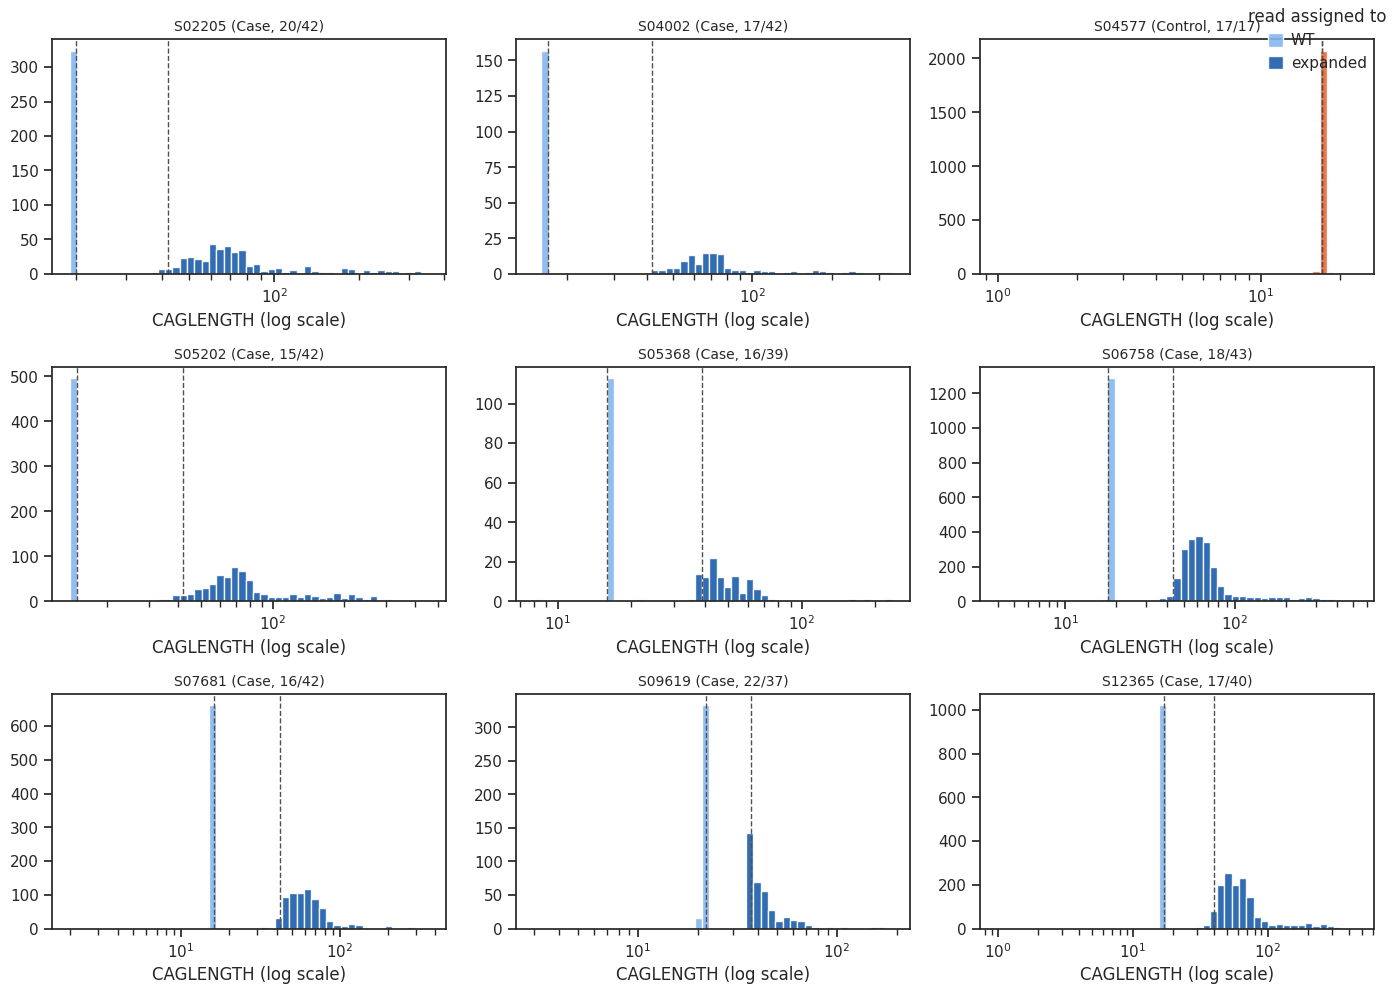

In [8]:
# genotype <-> donor check: WT reads must sit at WT_germline, expanded reads start around EXP_germline
check = []
for donor, o in hd.obs.groupby(SAMPLE_VARIABLE):
    wt = o.loc[o["cag_allele"] == "WT", REPEAT_COL]
    ex = o.loc[o["cag_allele"] == "expanded", REPEAT_COL]
    check.append(dict(
        DONOR=donor, CAG=f'{o["WT_germline"].iloc[0]}/{o["EXP_germline"].iloc[0]}',
        mode_WT_reads=wt.mode().iloc[0] if len(wt) else np.nan,
        p10_expanded=ex.quantile(0.10) if len(ex) else np.nan,
        median_expanded=ex.median() if len(ex) else np.nan,
        p90_expanded=ex.quantile(0.90) if len(ex) else np.nan,
    ))
check = pd.DataFrame(check).set_index("DONOR").join(germline)
check["WT_mode_matches"] = (check["mode_WT_reads"] - check["WT_germline"]).abs() <= 1
display(check)
bad = check.index[check["mode_WT_reads"].notna() & ~check["WT_mode_matches"]].tolist()
if bad:
    print(f"ATTENTION: WT-read mode does not match the germline WT allele for {bad} -> check genotype/donor mapping")

# histograms per donor, log x-axis, with germline alleles
donors = sorted(hd.obs[SAMPLE_VARIABLE].unique())
fig, axes = plt.subplots(3, 3, figsize=(14, 10), squeeze=False)
allele_colors = {"WT": "#86b6ef", "expanded": "#1c5cab", "no_expanded_allele": "#eb6834"}
for ax, donor in zip(axes.flat, donors):
    o = hd.obs[(hd.obs[SAMPLE_VARIABLE] == donor) & hd.obs[REPEAT_COL].notna()]
    bins = np.logspace(np.log10(max(o[REPEAT_COL].min(), 1)), np.log10(o[REPEAT_COL].max() + 1), 50)
    for allele, col in allele_colors.items():
        x = o.loc[o["cag_allele"] == allele, REPEAT_COL]
        if len(x):
            ax.hist(x, bins=bins, color=col, label=allele, alpha=0.9)
    for v in [germline.loc[donor, "WT_germline"], germline.loc[donor, "EXP_germline"]]:
        ax.axvline(v, color="#52514e", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(f'{donor} ({o["Status"].iloc[0]}, {check.loc[donor, "CAG"]})', fontsize=10)
    ax.set_xlabel("CAGLENGTH (log scale)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", title="read assigned to")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/cag_reads_by_donor.png", dpi=150)
plt.show()

ct,Matrix,Patch
DONOR,,
S02205,379,51
S04002,106,15
S05202,600,67
S05368,66,43
S06758,1748,456
S07681,615,89
S09619,320,51
S12365,1207,182


Matrix: 5041 cells, 8/8 donors with >= 10 cells; largest donor = S06758 (35% of cells)
Patch: 954 cells, 8/8 donors with >= 10 cells; largest donor = S06758 (48% of cells)


has_CAG_read,False,True
ct,,
Matrix,31164.0,60448.0
Patch,36161.0,61708.0


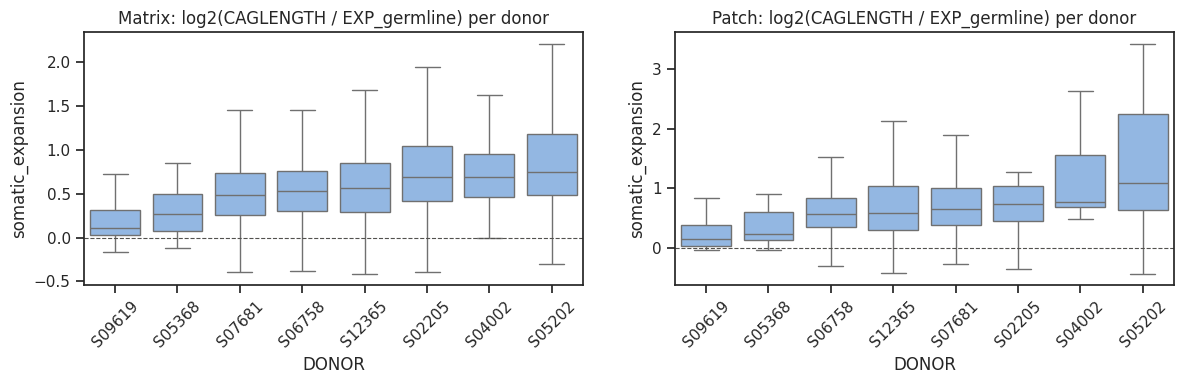

In [9]:
# cells available per donor x cell type, donor imbalance, and selection bias of HTT capture
n_tab = pd.crosstab(hd.obs.loc[hd.obs["in_analysis"], SAMPLE_VARIABLE], hd.obs.loc[hd.obs["in_analysis"], "ct"])
display(n_tab)

for ct in CELL_TYPES:
    n = n_tab[ct]
    kept = n[n >= MIN_CELLS_PER_DONOR]
    print(f"{ct}: {n.sum()} cells, {len(kept)}/{len(n)} donors with >= {MIN_CELLS_PER_DONOR} cells; "
          f"largest donor = {n.idxmax()} ({n.max() / n.sum():.0%} of cells)")
    if (n < MIN_CELLS_PER_DONOR).any():
        print(f"  ATTENTION: {n[n < MIN_CELLS_PER_DONOR].to_dict()} below {MIN_CELLS_PER_DONOR} cells -> dropped in Section 10")
    assert len(kept) >= MIN_DONORS, f"{ct}: fewer than {MIN_DONORS} donors with enough cells"

# Cells with a CAG read are cells where an HTT molecule was captured -> expect higher depth.
# NEBULA's offset handles depth, but keep in mind the analysed cells are not a random sample of MSNs.
case_msn = hd.obs[hd.obs["Status"] == "Case"]
display(case_msn.groupby([ "ct", case_msn[REPEAT_COL].notna().rename("has_CAG_read")])[LIBRARY_SIZE_COL].median().unstack())

fig, axes = plt.subplots(1, len(CELL_TYPES), figsize=(6 * len(CELL_TYPES), 4), squeeze=False)
for ax, ct in zip(axes[0], CELL_TYPES):
    o = hd.obs[hd.obs["in_analysis"] & (hd.obs["ct"] == ct)]
    order = o.groupby(SAMPLE_VARIABLE)[TESTED_TERM].median().sort_values().index
    sns.boxplot(data=o, x=SAMPLE_VARIABLE, y=TESTED_TERM, order=order, color="#86b6ef", showfliers=False, ax=ax)
    ax.axhline(0, color="#52514e", lw=0.8, ls="--")
    ax.set_title(f"{ct}: log2(CAGLENGTH / EXP_germline) per donor")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/somatic_expansion_by_donor.png", dpi=150)
plt.show()

# 6. Fit or load the healthy-reference PCA model

One PCA **per cell type**, fitted on BICAN caudate cells only. A joint Matrix + Patch PCA would put Matrix-vs-Patch identity on its first axis, and that axis is constant inside each NEBULA model.

Steps reuse `nebula_utils.calculate_pca` unchanged, which is the same code the `PCA_nebula` pipeline uses:

1. **Shared gene universe.** BICAN has no Ensembl IDs, so genes are matched on symbols that occur in both datasets (about 21k). Library-size normalisation is computed on this shared gene set in *both* datasets, so cell size factors are defined the same way. HVGs can only come from genes that HD also has, so no gene is zero-filled during projection.
2. `normalize_total(1e4)` → `log1p` → 3000 HVGs (BICAN only) → `StandardScaler` with BICAN mean and variance → PCA (full SVD, `random_state=42`).
3. Saved to `PCA_REF_DIR/{ct}/`:
   * `shared_genes.txt`: gene universe *and* order used for normalisation.
   * `healthy_stats.csv`: HVG list and order, with BICAN mean and variance (the scaler).
   * `gene_loadings.csv`: loadings.
   * `healthy_pcs.csv`: BICAN scores.
   * `pca_reference_meta.json`: parameters, explained variance, and sha256 of every artifact.

With `FORCE_REFIT_PCA = False`, the saved model is **always reloaded from disk**, both right after a fit and in later runs, and checked first:
* the artifact hashes are unchanged;
* every model gene exists in the current BICAN and HD data;
* the BICAN source files and the exact set of reference cells match.

A self-test then re-projects BICAN cells through the *projection* code path and requires their saved scores to be reproduced.

In [10]:
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def cells_sha256(names):
    return hashlib.sha256("\n".join(sorted(map(str, names))).encode()).hexdigest()

def pca_ref_paths(ct):
    d = f"{PCA_REF_DIR}/{ct}"
    return dict(dir=d, genes=f"{d}/shared_genes.txt", stats=f"{d}/healthy_stats.csv",
                loadings=f"{d}/gene_loadings.csv", scores=f"{d}/healthy_pcs.csv", meta=f"{d}/pca_reference_meta.json")


def fit_reference_pca(ct, bican_ct, shared_genes):
    paths = pca_ref_paths(ct)
    if os.path.exists(paths["dir"]):
        shutil.rmtree(paths["dir"])
    os.makedirs(paths["dir"])

    ref = bican_ct[:, shared_genes].copy()     # normalisation is computed on the shared gene set
    ref.X = ref.X.astype(np.float32)
    res = nebula_utils.calculate_pca(ref, "calculate", paths["dir"], N_PCS_TO_USE=N_PCS_REFERENCE)
    plt.show()

    n_hvg = res["df_stats"].shape[0]
    # genes are unit-variance after scaling -> total variance = n_hvg
    evr = res["pcs"].var(axis=0) / n_hvg

    with open(paths["genes"], "w") as f:
        f.write("\n".join(shared_genes) + "\n")

    meta = dict(
        cell_type=ct,
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        bican_files=CT_MAP[ct],
        reference_cells="BICAN caudate (spline d < 0), donors with a spline fit",
        n_cells=int(ref.n_obs),
        n_donors=int(bican_ct.obs["donor_id"].nunique()),
        bican_cells_sha256=cells_sha256(bican_ct.obs_names),
        n_shared_genes=len(shared_genes),
        n_hvg=int(n_hvg),
        preprocessing=("utils.nebula_with_factors.calculate_pca on raw counts restricted to shared_genes: "
                       "normalize_total(target_sum=1e4) -> log1p -> highly_variable_genes(n_top_genes=3000, flavor=seurat) "
                       "-> StandardScaler(BICAN mean/var) -> PCA(50, svd_solver=full, random_state=42)"),
        n_pcs_saved=N_PCS_REFERENCE,
        explained_variance_ratio={f"PC_{i+1}": float(v) for i, v in enumerate(evr[:N_PCS_REFERENCE])},
        sha256={k: file_sha256(paths[k]) for k in ["genes", "stats", "loadings", "scores"]},
    )
    with open(paths["meta"], "w") as f:
        json.dump(meta, f, indent=2)
    print(f"{ct}: reference PCA saved to {paths['dir']}")


def load_reference_pca(ct, bican_ct, hd_genes):
    """Load the saved model and refuse to continue if it doesn't match the current inputs."""
    paths = pca_ref_paths(ct)
    with open(paths["meta"]) as f:
        meta = json.load(f)

    for k, sha in meta["sha256"].items():
        assert file_sha256(paths[k]) == sha, f"{ct}: {paths[k]} changed since the model was fitted"
    assert meta["bican_files"] == CT_MAP[ct], f"{ct}: model was fitted on {meta['bican_files']}"
    assert meta["bican_cells_sha256"] == cells_sha256(bican_ct.obs_names), \
        f"{ct}: BICAN reference cells differ from those used to fit the model -> set FORCE_REFIT_PCA = True"

    shared_genes = pd.read_csv(paths["genes"], header=None)[0].astype(str).tolist()
    df_stats = pd.read_csv(paths["stats"], index_col=0)
    df_loadings = pd.read_csv(paths["loadings"], index_col=0)
    df_scores = pd.read_csv(paths["scores"], dtype={"barcode": str}).set_index("barcode")

    assert df_stats.index.equals(df_loadings.index), "stats / loadings gene order differ"
    assert set(df_loadings.index) <= set(shared_genes), "HVG outside the shared gene universe"
    assert df_loadings.shape[1] == meta["n_pcs_saved"]
    assert (df_stats["var_train"] > 0).all()
    missing_hd = [g for g in shared_genes if g not in hd_genes]
    missing_bican = [g for g in shared_genes if g not in bican_ct.var_names]
    assert not missing_hd and not missing_bican, \
        f"{ct}: {len(missing_hd)} model genes missing in HD, {len(missing_bican)} in BICAN"

    print(f"{ct}: loaded reference PCA ({meta['created']}): {meta['n_cells']} BICAN cells, "
          f"{meta['n_shared_genes']} shared genes, {meta['n_hvg']} HVGs, {meta['n_pcs_saved']} PCs")
    return dict(meta=meta, shared_genes=shared_genes, df_stats=df_stats, df_loadings=df_loadings,
                df_scores=df_scores, pcs=df_loadings.columns.tolist(),
                evr=pd.Series(meta["explained_variance_ratio"]))


def project_onto_reference(adata_counts, ct, saving_folder):
    """Project cells (raw counts in .X) into the saved healthy PCA space of `ct`."""
    ref = pca_ref[ct]
    os.makedirs(saving_folder, exist_ok=True)
    a = adata_counts[:, ref["shared_genes"]].copy()   # same gene universe + order as the fit
    a.X = a.X.astype(np.float32)
    res = nebula_utils.calculate_pca(a, "project", saving_folder,
                                     df_stats=ref["df_stats"], df_loadings=ref["df_loadings"])
    return res["df_pcs"].set_index("barcode")

Matrix: 21026 genes shared by BICAN (37905) and HD (36943)
Normalising
HVG
Scaling
PCA on Healthy
Done.


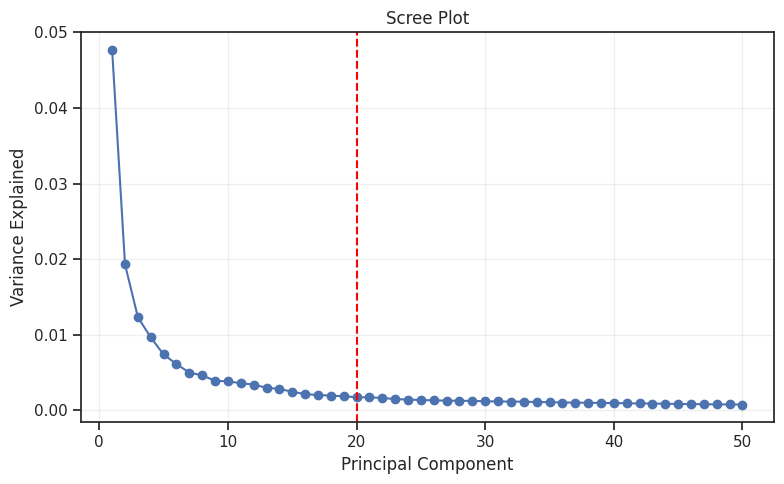

Matrix: reference PCA saved to /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/pca_reference/Matrix
Matrix: loaded reference PCA (2026-10-29T18:38:58): 95732 BICAN cells, 21026 shared genes, 3000 HVGs, 20 PCs
Patch: 21026 genes shared by BICAN (37905) and HD (36943)
Normalising
HVG
Scaling
PCA on Healthy
Done.


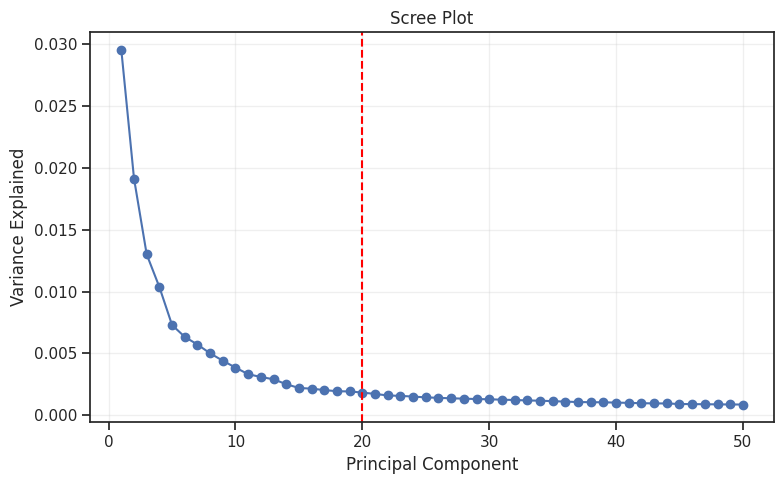

Patch: reference PCA saved to /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/pca_reference/Patch
Patch: loaded reference PCA (2026-10-29T18:39:13): 17188 BICAN cells, 21026 shared genes, 3000 HVGs, 20 PCs


In [11]:
pca_ref = {}
for ct in CELL_TYPES:
    hd_genes = set(hd.var_names)
    shared_genes = [g for g in bican[ct].var_names if g in hd_genes]   # BICAN order
    print(f"{ct}: {len(shared_genes)} genes shared by BICAN ({bican[ct].n_vars}) and HD ({hd.n_vars})")

    if FORCE_REFIT_PCA or not os.path.exists(pca_ref_paths(ct)["meta"]):
        fit_reference_pca(ct, bican[ct], shared_genes)
    pca_ref[ct] = load_reference_pca(ct, bican[ct], hd_genes)

    # attach BICAN scores
    sc_ = pca_ref[ct]["df_scores"]
    assert sc_.index.isin(bican[ct].obs_names).all() and len(sc_) == bican[ct].n_obs
    bican[ct].obs = bican[ct].obs.drop(columns=pca_ref[ct]["pcs"], errors="ignore").join(sc_)

In [12]:
# Self-test: the projection path must reproduce the fitted BICAN scores (guards against preprocessing drift)
rng = np.random.default_rng(0)
for ct in CELL_TYPES:
    idx = rng.choice(bican[ct].n_obs, size=min(3000, bican[ct].n_obs), replace=False)
    sub = bican[ct][idx]
    with tempfile.TemporaryDirectory() as tmp:
        proj = project_onto_reference(sub, ct, tmp)
    saved = pca_ref[ct]["df_scores"].loc[proj.index, proj.columns]
    rel_err = (proj - saved).abs().max() / saved.std()
    print(f"{ct}: max |projected - fitted| / sd per PC = {rel_err.max():.2e}")
    assert rel_err.max() < 1e-3, f"{ct}: projection does not reproduce the fitted reference scores"

Normalising
Scaling
PCA on Diseased
Done.
Matrix: max |projected - fitted| / sd per PC = 1.69e-05
Normalising
Scaling
PCA on Diseased
Done.
Patch: max |projected - fitted| / sd per PC = 1.15e-05


# 7. Project HD cells into the reference space

All HD Matrix / Patch cells (Case and Control) are projected using the BICAN normalisation, HVGs, mean/variance and loadings. Each cell is projected on its own, so including or excluding other cells does not change its score. Scores are written to `HD_PROJ_DIR/{ct}/diseased_pcs.csv`. That file name comes from `calculate_pca`; here it holds all HD cells.

`PC_k` columns in `hd.obs` always refer to the reference PCA of the cell's **own** cell type. Never compare `PC_1` of a Matrix cell with `PC_1` of a Patch cell.

In [13]:
all_pcs = sorted({pc for ct in CELL_TYPES for pc in pca_ref[ct]["pcs"]}, key=lambda s: int(s.split("_")[1]))
hd.obs = hd.obs.drop(columns=all_pcs, errors="ignore")
for pc in all_pcs:
    hd.obs[pc] = np.nan

for ct in CELL_TYPES:
    hd_ct = hd[hd.obs["ct"] == ct]
    df_proj = project_onto_reference(hd_ct, ct, f"{HD_PROJ_DIR}/{ct}")
    assert df_proj.index.equals(hd_ct.obs_names)
    hd.obs.loc[df_proj.index, df_proj.columns] = df_proj.values
    print(f"{ct}: projected {len(df_proj)} HD cells")

assert not hd.obs.loc[:, pca_ref[CELL_TYPES[0]]["pcs"]].isna().any().any()

Normalising
Scaling
PCA on Diseased
Done.
Matrix: projected 57528 HD cells
Normalising
Scaling
PCA on Diseased
Done.
Patch: projected 14193 HD cells


# 8. Inspect the reference PCs

Spatial ground truth exists only in BICAN (HD is dissociated nuclei). Each PC is therefore judged on three questions:

| question | metric | data |
|---|---|---|
| Is it spatial? | Spearman ρ with dorsal–ventral spline position `r` (and distance `d`); η² of spatial `zone` | BICAN |
| Is it something else? | η² of donor; η² of D1/D2 subtype | BICAN, HD |
| Does it transfer? | `var_ratio` = var(HD projected) / var(BICAN); `shift_sd` = (mean HD − mean BICAN) / sd BICAN; η² of HD `zone` | HD (all MSNs of that type) |
| Does it overlap the predictor? | LMM `PC ~ somatic_expansion + Age + pct_counts_mt + msn_subtype + (1\|DONOR)`: standardised β and FDR for `somatic_expansion` | HD analysis cells |

How to read them:
* **`shift_sd`**: a constant offset between Slide-tags BICAN and 10x HD is expected (different chemistry and depth). The model intercept absorbs it, so on its own it is harmless.
* **`var_ratio`**: values ≪ 1 mean the axis barely varies in HD and the PC adds nothing. Values ≫ 1 mean the projection mostly picks up HD-specific noise or technical variation along that gene combination.
* **Donor-dominated PCs** have high η² of donor in *healthy BICAN*. They mostly encode sample effects (dissection, quality) and are largely redundant with the donor random effect. HD donor η² is reported but **not** used to flag PCs: HD donors were dissected at different dorsal–ventral levels, so a genuinely spatial PC is expected to differ between HD donors (e.g. Patch PC_1).
* **D1/D2 PCs** are redundant with the `msn_subtype` covariate.
* **HD `zone`** was itself predicted from expression by mapping to BICAN, so its η² is a *consistency* check, not independent truth.
* **Repeat association** is the key scientific risk. If a PC is associated with `somatic_expansion`, adjusting for it removes the part of the repeat effect that runs along that axis. Two readings are possible: (a) position confounds the association (expansion differs along the dorsal–ventral axis *and* expression follows position), so adjusting is right; or (b) repeat expansion itself shifts cells along that expression axis, so adjusting removes real disease signal. The data cannot tell these apart. That is why the baseline and PC models are compared in Section 11, using Handsaker phase C genes as a positive control.

The PC filter of the original pipeline (keep PCs *not* associated with the condition) is **not** applied here, because there is no case/control variable. Repeat association is reported instead, and you decide.

In [14]:
def eta2(values, groups):
    """Fraction of variance of `values` explained by the categorical `groups`."""
    df = pd.DataFrame({"v": np.asarray(values, dtype=float), "g": pd.Series(groups).astype(str).values}).dropna()
    df = df[df["g"] != "nan"]
    if df["g"].nunique() < 2:
        return np.nan
    grand = df["v"].mean()
    between = df.groupby("g")["v"].transform("mean") - grand
    return float((between ** 2).sum() / ((df["v"] - grand) ** 2).sum())


def spearman(x, y):
    m = pd.notna(x) & pd.notna(y)
    return stats.spearmanr(np.asarray(x)[m], np.asarray(y)[m])[0]


def pc_repeat_lmm(df, pc):
    """Within-donor association of a (standardised) PC with repeat length."""
    d = df[[pc, TESTED_TERM, "Age", "pct_counts_mt", "msn_subtype", SAMPLE_VARIABLE]].dropna().copy()
    d["y"] = (d[pc] - d[pc].mean()) / d[pc].std()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = smf.mixedlm(f"y ~ {TESTED_TERM} + Age + pct_counts_mt + C(msn_subtype)",
                              d, groups=d[SAMPLE_VARIABLE]).fit(reml=True)
        return fit.params[TESTED_TERM], fit.pvalues[TESTED_TERM]
    except Exception as e:
        print(f"  LMM failed for {pc}: {e}")
        return np.nan, np.nan


diag = {}
for ct in CELL_TYPES:
    pcs = pca_ref[ct]["pcs"]
    b = bican[ct].obs
    h_all = hd.obs[hd.obs["ct"] == ct]
    h_an = h_all[h_all["in_analysis"]]
    rows = []
    for pc in pcs:
        beta, p = pc_repeat_lmm(h_an, pc)
        rows.append(dict(
            PC=pc,
            evr_bican=pca_ref[ct]["evr"][pc],
            rho_r_bican=spearman(b[pc], b["r"]),
            rho_d_bican=spearman(b[pc], b["d"]),
            eta2_zone_bican=eta2(b[pc], b["zone"]),
            eta2_donor_bican=eta2(b[pc], b["donor_id"]),
            eta2_subtype_bican=eta2(b[pc], b["msn_subtype"]),
            var_ratio_hd=h_all[pc].var() / b[pc].var(),
            shift_sd_hd=(h_all[pc].mean() - b[pc].mean()) / b[pc].std(),
            eta2_zone_hd=eta2(h_all[pc], h_all[HD_ZONE_COL[ct]]),
            eta2_donor_hd=eta2(h_an[pc], h_an[SAMPLE_VARIABLE]),
            eta2_subtype_hd=eta2(h_an[pc], h_an["msn_subtype"]),
            rho_repeat_hd=spearman(h_an[pc], h_an[TESTED_TERM]),
            beta_repeat_lmm=beta, p_repeat_lmm=p,
        ))
    df = pd.DataFrame(rows).set_index("PC")
    ok = df["p_repeat_lmm"].notna()
    df["fdr_repeat_lmm"] = np.nan
    df.loc[ok, "fdr_repeat_lmm"] = multipletests(df.loc[ok, "p_repeat_lmm"], method="fdr_bh")[1]

    # heuristic flags (only used to print a suggestion)
    df["spatial"] = (df["rho_r_bican"].abs() >= 0.2) | (df["eta2_zone_bican"] >= 0.1)
    df["transfers"] = df["var_ratio_hd"].between(*TRANSFER_VAR_RATIO_RANGE)
    df["donor_dominated"] = df["eta2_donor_bican"] > MAX_DONOR_ETA2
    df["subtype_axis"] = df["eta2_subtype_bican"] > MAX_SUBTYPE_ETA2
    # with thousands of cells nearly every PC reaches FDR < 0.05, so require a non-trivial effect too
    df["repeat_associated"] = (df["fdr_repeat_lmm"] < 0.05) & (df["beta_repeat_lmm"].abs() >= MIN_REPEAT_BETA)
    df["suggested"] = df["transfers"] & ~df["donor_dominated"] & ~df["subtype_axis"]
    diag[ct] = df
    df.to_csv(f"{PCA_REF_DIR}/{ct}/pc_diagnostics.csv")

    print(f"\n######## {ct} ########")
    display(df.round(3))
    print(f"{ct}: suggested PCs (transfer OK, not donor- or D1/D2-dominated): {df.index[df['suggested']].tolist()}")
    print(f"{ct}: of which spatial: {df.index[df['suggested'] & df['spatial']].tolist()}")
    print(f"{ct}: repeat-associated (FDR < 0.05 and |beta| >= {MIN_REPEAT_BETA}): {df.index[df['repeat_associated']].tolist()}")


######## Matrix ########


,evr_bican,rho_r_bican,rho_d_bican,eta2_zone_bican,eta2_donor_bican,eta2_subtype_bican,var_ratio_hd,shift_sd_hd,eta2_zone_hd,eta2_donor_hd,...,rho_repeat_hd,beta_repeat_lmm,p_repeat_lmm,fdr_repeat_lmm,spatial,transfers,donor_dominated,subtype_axis,repeat_associated,suggested
PC,,,,,,,,,,,,,,,,,,,,,
PC_1,0.048,-0.741,0.030,0.607,0.238,0.008,0.242,-0.339,0.235,0.218,...,0.018,0.084,0.000,0.000,True,False,False,False,False,False
PC_2,0.019,0.380,0.162,0.196,0.442,0.001,1.117,0.179,0.406,0.816,...,-0.010,-0.048,0.000,0.000,True,True,False,False,False,True
PC_3,0.012,0.311,0.142,0.093,0.585,0.002,0.743,-0.103,0.133,0.338,...,-0.132,0.053,0.001,0.002,True,True,True,False,False,False
PC_4,0.010,-0.097,-0.127,0.013,0.011,0.919,0.878,-0.330,0.025,0.044,...,0.037,-0.006,0.512,0.569,False,True,False,True,False,False
PC_5,0.007,0.180,0.182,0.090,0.483,0.006,0.498,-0.267,0.190,0.434,...,0.041,-0.054,0.002,0.003,False,True,False,False,False,True
PC_6,0.006,-0.044,-0.035,0.202,0.375,0.001,0.514,0.157,0.036,0.283,...,-0.092,-0.051,0.011,0.019,True,True,False,False,False,True
PC_7,0.005,-0.175,-0.217,0.127,0.121,0.005,0.758,-0.515,0.082,0.230,...,-0.071,-0.237,0.000,0.000,True,True,False,False,True,True
PC_8,0.005,0.022,-0.646,0.473,0.158,0.008,0.486,-0.455,0.166,0.600,...,-0.032,0.021,0.154,0.219,True,True,False,False,False,True
PC_9,0.004,0.110,0.021,0.016,0.101,0.000,0.794,0.068,0.117,0.264,...,-0.076,0.125,0.000,0.000,False,True,False,False,True,True


Matrix: suggested PCs (transfer OK, not donor- or D1/D2-dominated): ['PC_2', 'PC_5', 'PC_6', 'PC_7', 'PC_8', 'PC_9', 'PC_10', 'PC_11', 'PC_12', 'PC_13', 'PC_14', 'PC_15', 'PC_16', 'PC_17', 'PC_18', 'PC_19', 'PC_20']
Matrix: of which spatial: ['PC_2', 'PC_6', 'PC_7', 'PC_8']
Matrix: repeat-associated (FDR < 0.05 and |beta| >= 0.1): ['PC_7', 'PC_9', 'PC_13', 'PC_16']

######## Patch ########


,evr_bican,rho_r_bican,rho_d_bican,eta2_zone_bican,eta2_donor_bican,eta2_subtype_bican,var_ratio_hd,shift_sd_hd,eta2_zone_hd,eta2_donor_hd,...,rho_repeat_hd,beta_repeat_lmm,p_repeat_lmm,fdr_repeat_lmm,spatial,transfers,donor_dominated,subtype_axis,repeat_associated,suggested
PC,,,,,,,,,,,,,,,,,,,,,
PC_1,0.029,-0.551,0.235,0.365,0.325,0.083,0.691,0.284,0.086,0.108,...,0.034,0.149,0.000,0.000,True,True,False,False,True,True
PC_2,0.019,0.510,0.179,0.287,0.450,0.007,1.658,0.006,0.362,0.787,...,-0.112,-0.128,0.000,0.000,True,True,False,False,True,True
PC_3,0.013,-0.264,-0.315,0.112,0.147,0.701,0.890,-0.212,0.033,0.126,...,0.030,-0.036,0.028,0.040,True,True,False,True,False,False
PC_4,0.010,0.304,0.126,0.092,0.448,0.056,0.620,-0.078,0.033,0.381,...,-0.085,0.081,0.003,0.006,True,True,False,False,False,True
PC_5,0.007,0.036,-0.286,0.113,0.252,0.080,0.948,0.079,0.031,0.486,...,0.012,0.013,0.610,0.718,True,True,False,False,False,True
PC_6,0.006,-0.014,-0.285,0.071,0.290,0.010,1.535,-0.400,0.105,0.046,...,-0.117,-0.257,0.000,0.000,False,True,False,False,True,True
PC_7,0.006,0.090,-0.193,0.047,0.345,0.000,1.981,0.199,0.032,0.268,...,0.028,0.151,0.000,0.000,False,True,False,False,True,True
PC_8,0.005,-0.119,-0.221,0.061,0.075,0.016,1.263,-0.387,0.031,0.088,...,-0.050,-0.107,0.007,0.011,False,True,False,False,True,True
PC_9,0.004,-0.042,0.015,0.031,0.271,0.001,3.523,-0.221,0.035,0.429,...,0.104,-0.002,0.946,0.946,False,False,False,False,False,False


Patch: suggested PCs (transfer OK, not donor- or D1/D2-dominated): ['PC_1', 'PC_2', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8', 'PC_11', 'PC_12', 'PC_13', 'PC_14', 'PC_15', 'PC_16', 'PC_17', 'PC_18', 'PC_19', 'PC_20']
Patch: of which spatial: ['PC_1', 'PC_2', 'PC_4', 'PC_5', 'PC_12', 'PC_13']
Patch: repeat-associated (FDR < 0.05 and |beta| >= 0.1): ['PC_1', 'PC_2', 'PC_6', 'PC_7', 'PC_8', 'PC_10', 'PC_11', 'PC_13', 'PC_15', 'PC_18', 'PC_20']


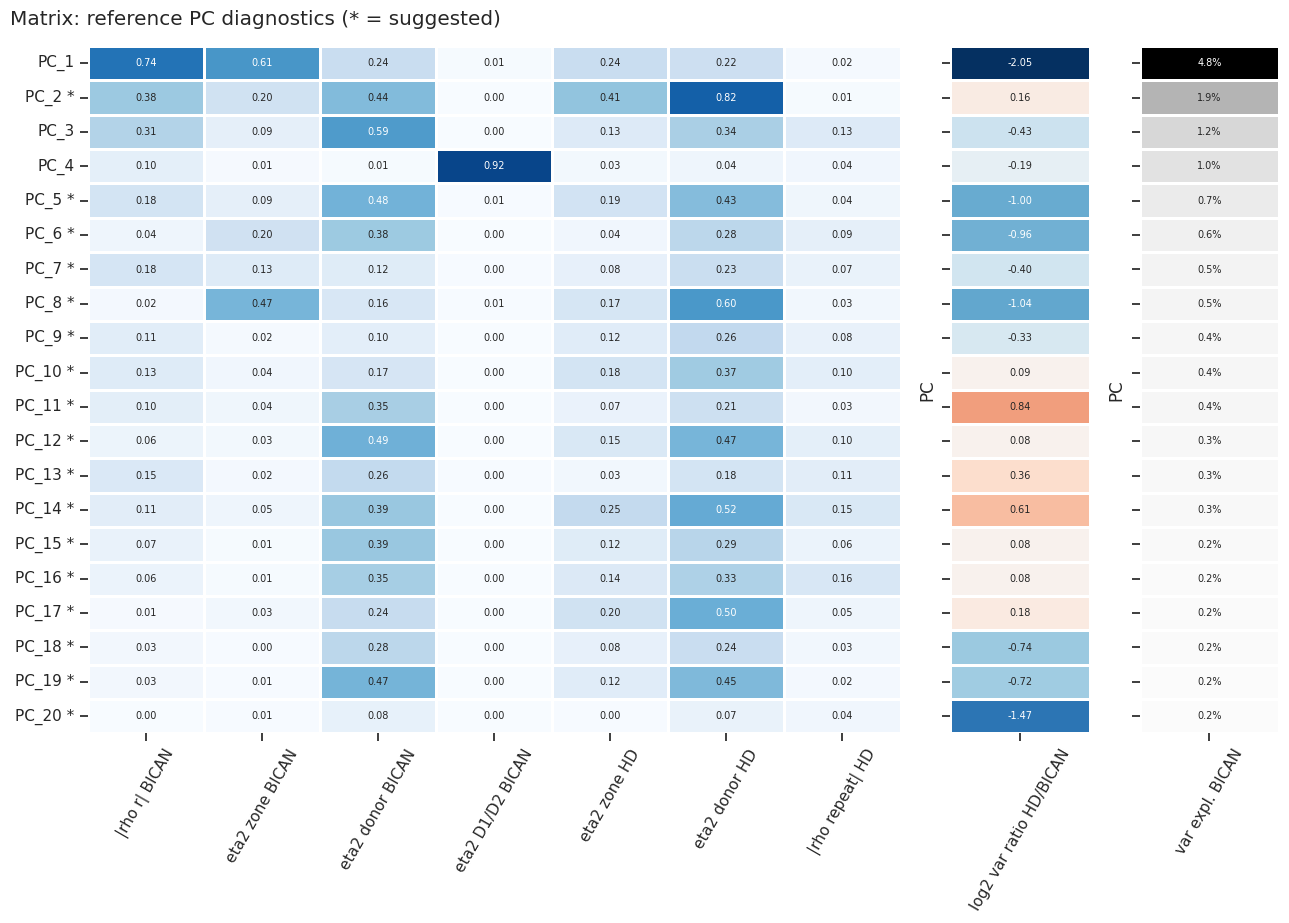

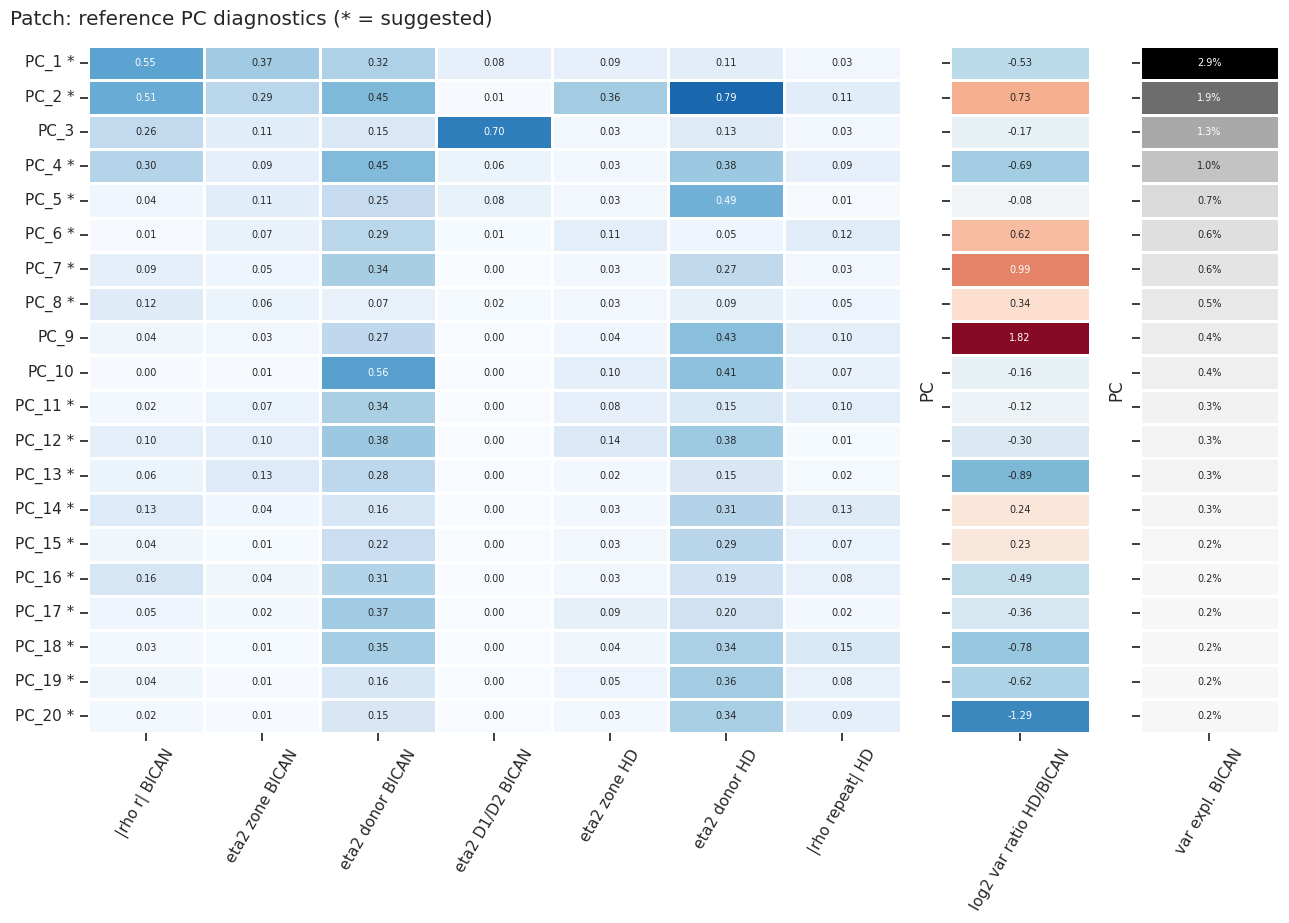

In [15]:
# Overview heatmap: left = 0..1 metrics (sequential), right = log2 var_ratio (diverging, 0 = same spread as BICAN)
abs_cols = {
    "|rho r| BICAN": lambda d: d["rho_r_bican"].abs(),
    "eta2 zone BICAN": lambda d: d["eta2_zone_bican"],
    "eta2 donor BICAN": lambda d: d["eta2_donor_bican"],
    "eta2 D1/D2 BICAN": lambda d: d["eta2_subtype_bican"],
    "eta2 zone HD": lambda d: d["eta2_zone_hd"],
    "eta2 donor HD": lambda d: d["eta2_donor_hd"],
    "|rho repeat| HD": lambda d: d["rho_repeat_hd"].abs(),
}
for ct in CELL_TYPES:
    d = diag[ct]
    m = pd.DataFrame({k: f(d) for k, f in abs_cols.items()})
    fig, axes = plt.subplots(1, 3, figsize=(13, 0.38 * len(d) + 1.8),
                             gridspec_kw=dict(width_ratios=[len(abs_cols), 1.2, 1.2]), sharey=True)
    sns.heatmap(m, vmin=0, vmax=1, cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7},
                cbar=False, linewidths=1, linecolor="white", ax=axes[0])
    sns.heatmap(np.log2(d[["var_ratio_hd"]]).rename(columns={"var_ratio_hd": "log2 var ratio HD/BICAN"}),
                vmin=-2, vmax=2, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
                cbar=False, linewidths=1, linecolor="white", ax=axes[1])
    sns.heatmap(d[["evr_bican"]].rename(columns={"evr_bican": "var expl. BICAN"}), cmap="Greys", vmin=0,
                annot=True, fmt=".1%", annot_kws={"size": 7}, cbar=False, linewidths=1, linecolor="white", ax=axes[2])
    for ax in axes:
        ax.tick_params(axis="x", rotation=60)
        ax.set_xlabel("")
    axes[0].set_ylabel("")
    axes[0].set_yticklabels([f"{pc} *" if d.loc[pc, "suggested"] else pc for pc in d.index], rotation=0)
    fig.suptitle(f"{ct}: reference PC diagnostics (* = suggested)", x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{ct}_pc_diagnostics_heatmap.png", dpi=150)
    plt.show()

### Spatial maps on one BICAN puck

Caudate cells of `SPATIAL_PLOT_DONOR`, coloured by PC score. Grey = all other cells of the puck (other cell types and the putamen side), for orientation. PC colour scale: diverging, centred on 0, clipped at the 99th percentile of |score|.

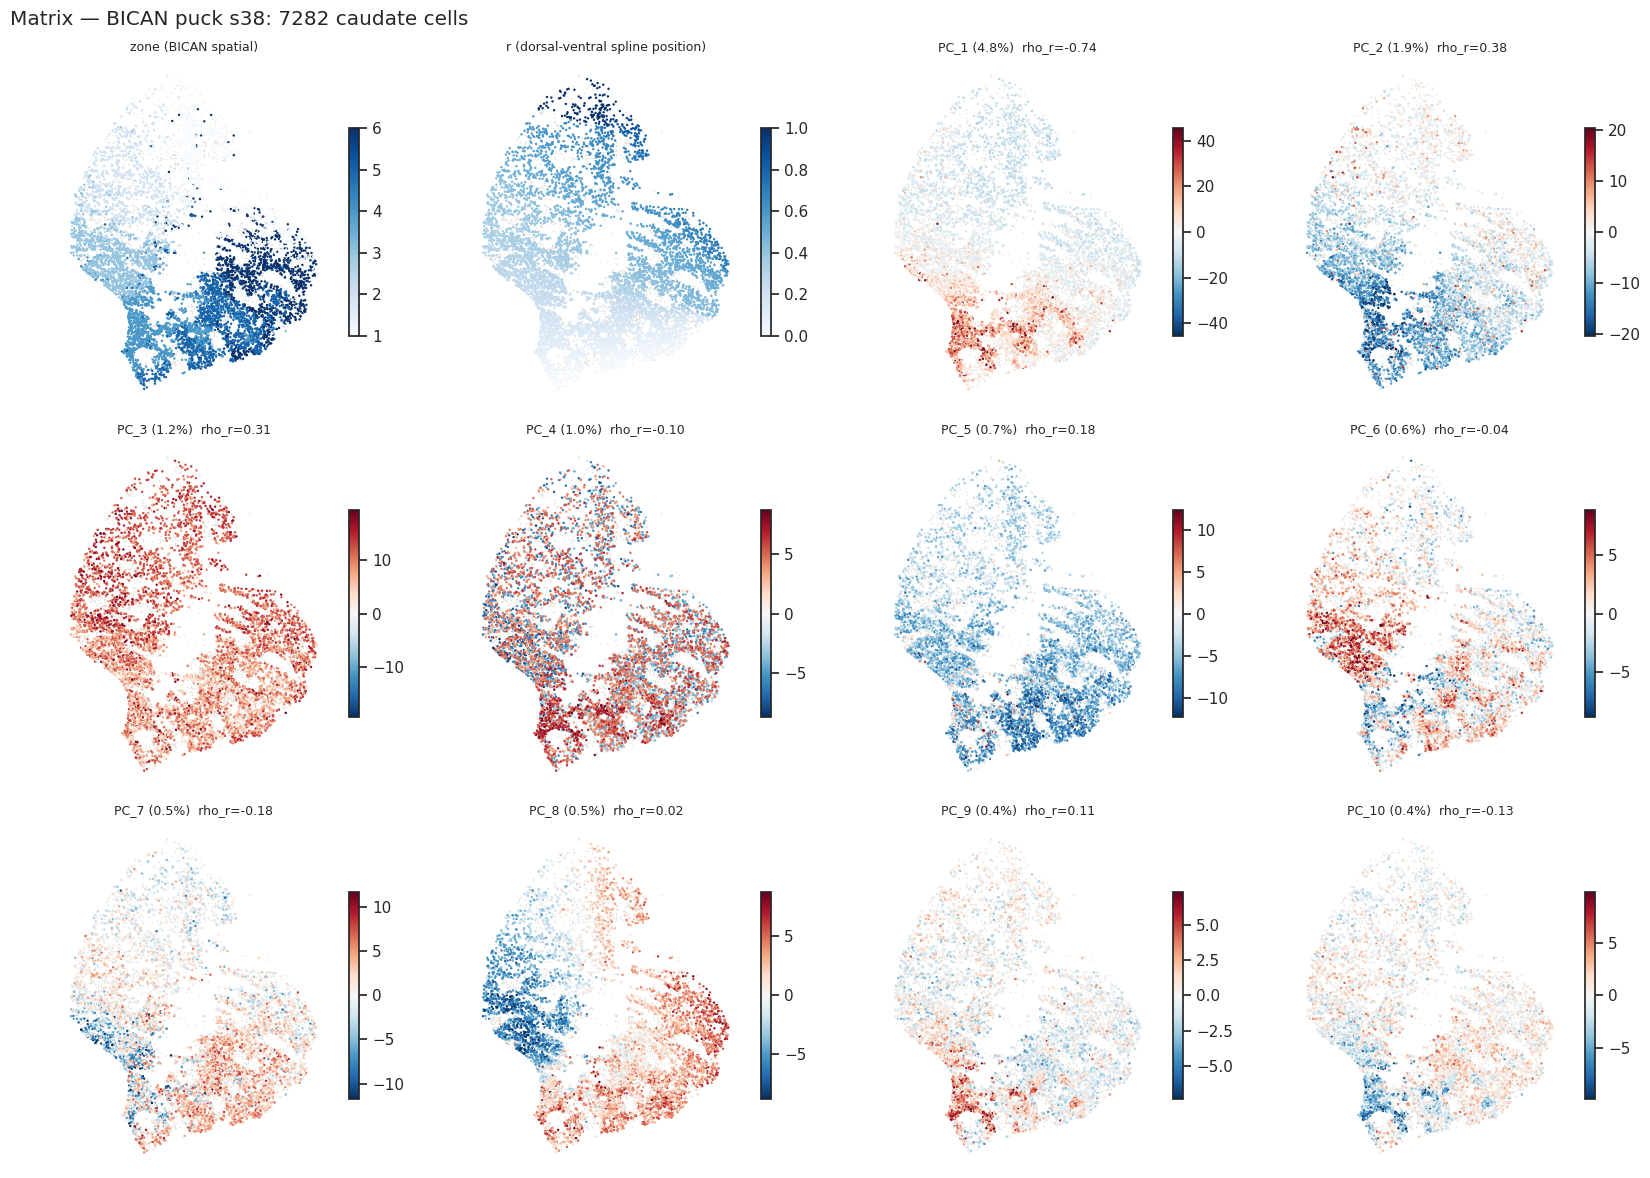

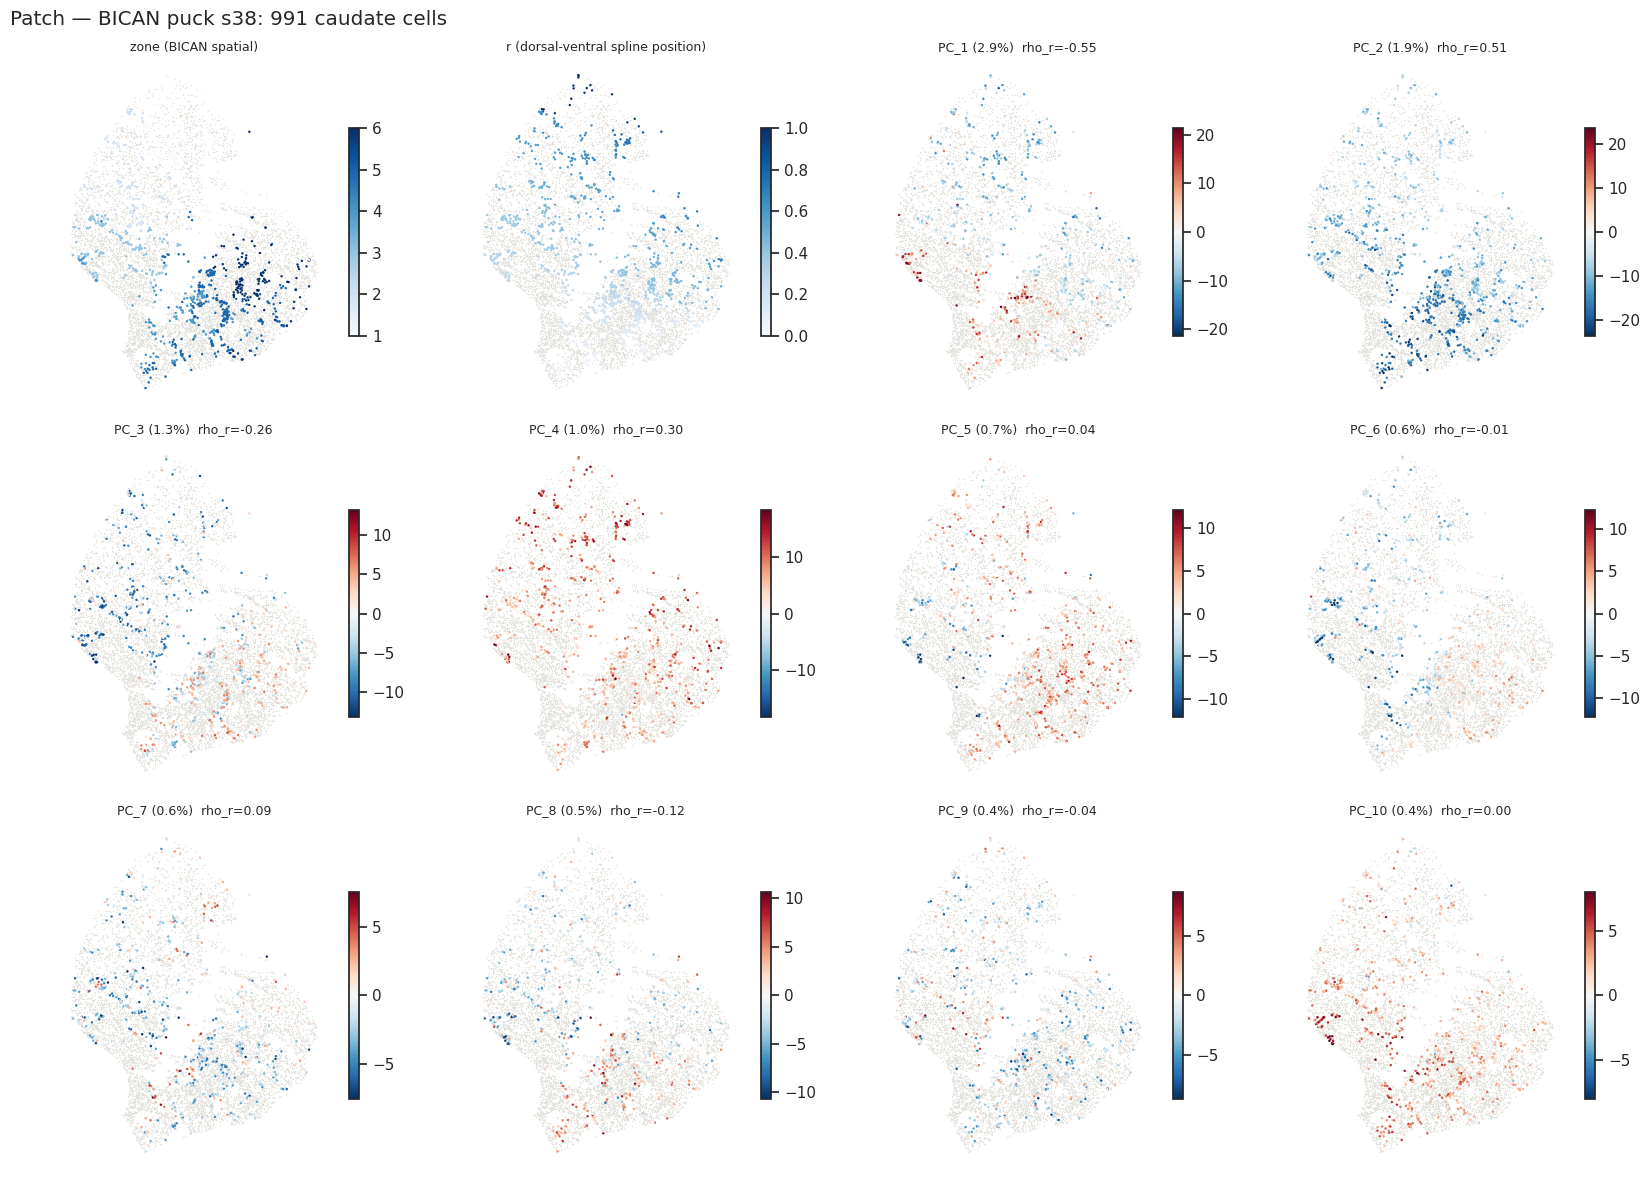

In [16]:
def plot_spatial_pcs(ct, donor, pcs_to_plot):
    b = bican[ct].obs
    s = b[b["donor_id"] == donor]
    bg = pd.read_csv(f"{SPLINES_DIR}/{donor}_x_y_with_splines.csv", index_col=0)
    panels = ["zone", "r", *pcs_to_plot]
    ncol = 4
    nrow = int(np.ceil(len(panels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4 * nrow), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, key in zip(axes.flat, panels):
        ax.scatter(bg["x"], bg["y"], s=1, c="#e2e1dc", linewidths=0, rasterized=True)
        if key in ("zone", "r"):
            vals = s[key].astype(float)
            sca = ax.scatter(s["x"], s["y"], c=vals, s=3, cmap="Blues", linewidths=0, rasterized=True)
            title = "zone (BICAN spatial)" if key == "zone" else "r (dorsal-ventral spline position)"
        else:
            lim = np.nanpercentile(np.abs(s[key]), 99)
            sca = ax.scatter(s["x"], s["y"], c=s[key], s=3, cmap="RdBu_r",
                             norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), linewidths=0, rasterized=True)
            d = diag[ct].loc[key]
            title = f"{key} ({d['evr_bican']:.1%})  rho_r={d['rho_r_bican']:.2f}"
        plt.colorbar(sca, ax=ax, shrink=0.6)
        ax.set_title(title, fontsize=9)
        ax.set_aspect("equal")
    fig.suptitle(f"{ct} — BICAN puck {donor}: {len(s)} caudate cells", x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{ct}_spatial_pcs_{donor}.png", dpi=150)
    plt.show()

for ct in CELL_TYPES:
    plot_spatial_pcs(ct, SPATIAL_PLOT_DONOR, pca_ref[ct]["pcs"][:N_PCS_TO_PLOT])

### Score distributions: BICAN vs projected HD, and per donor

Top row: BICAN vs HD Control vs HD Case. If the PC transfers, the shapes should be similar; a pure offset is harmless. Bottom row: BICAN D1 vs D2. Boxplots: one box per donor, coloured by dataset/status.

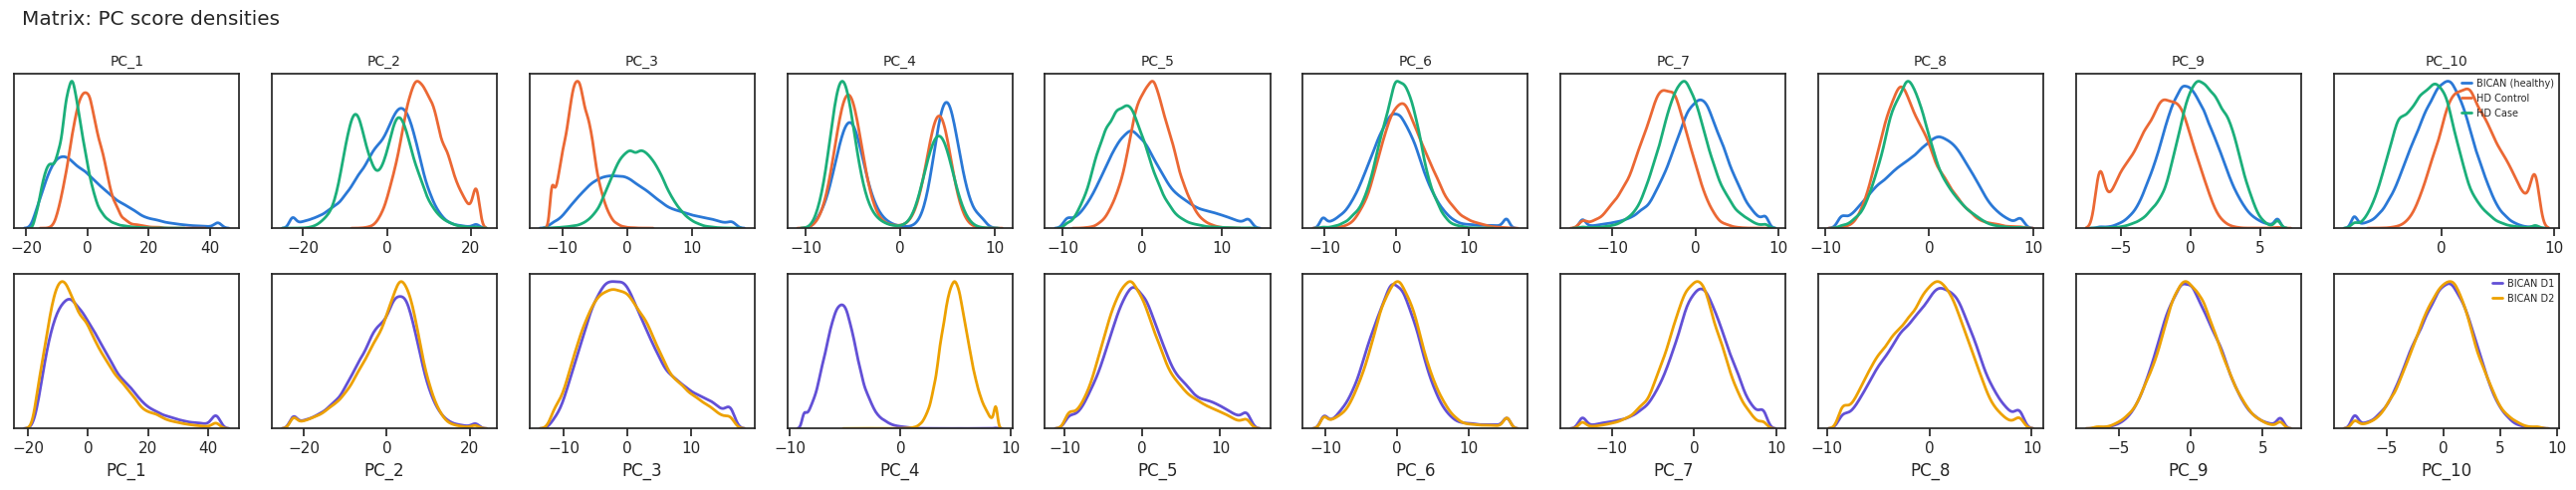

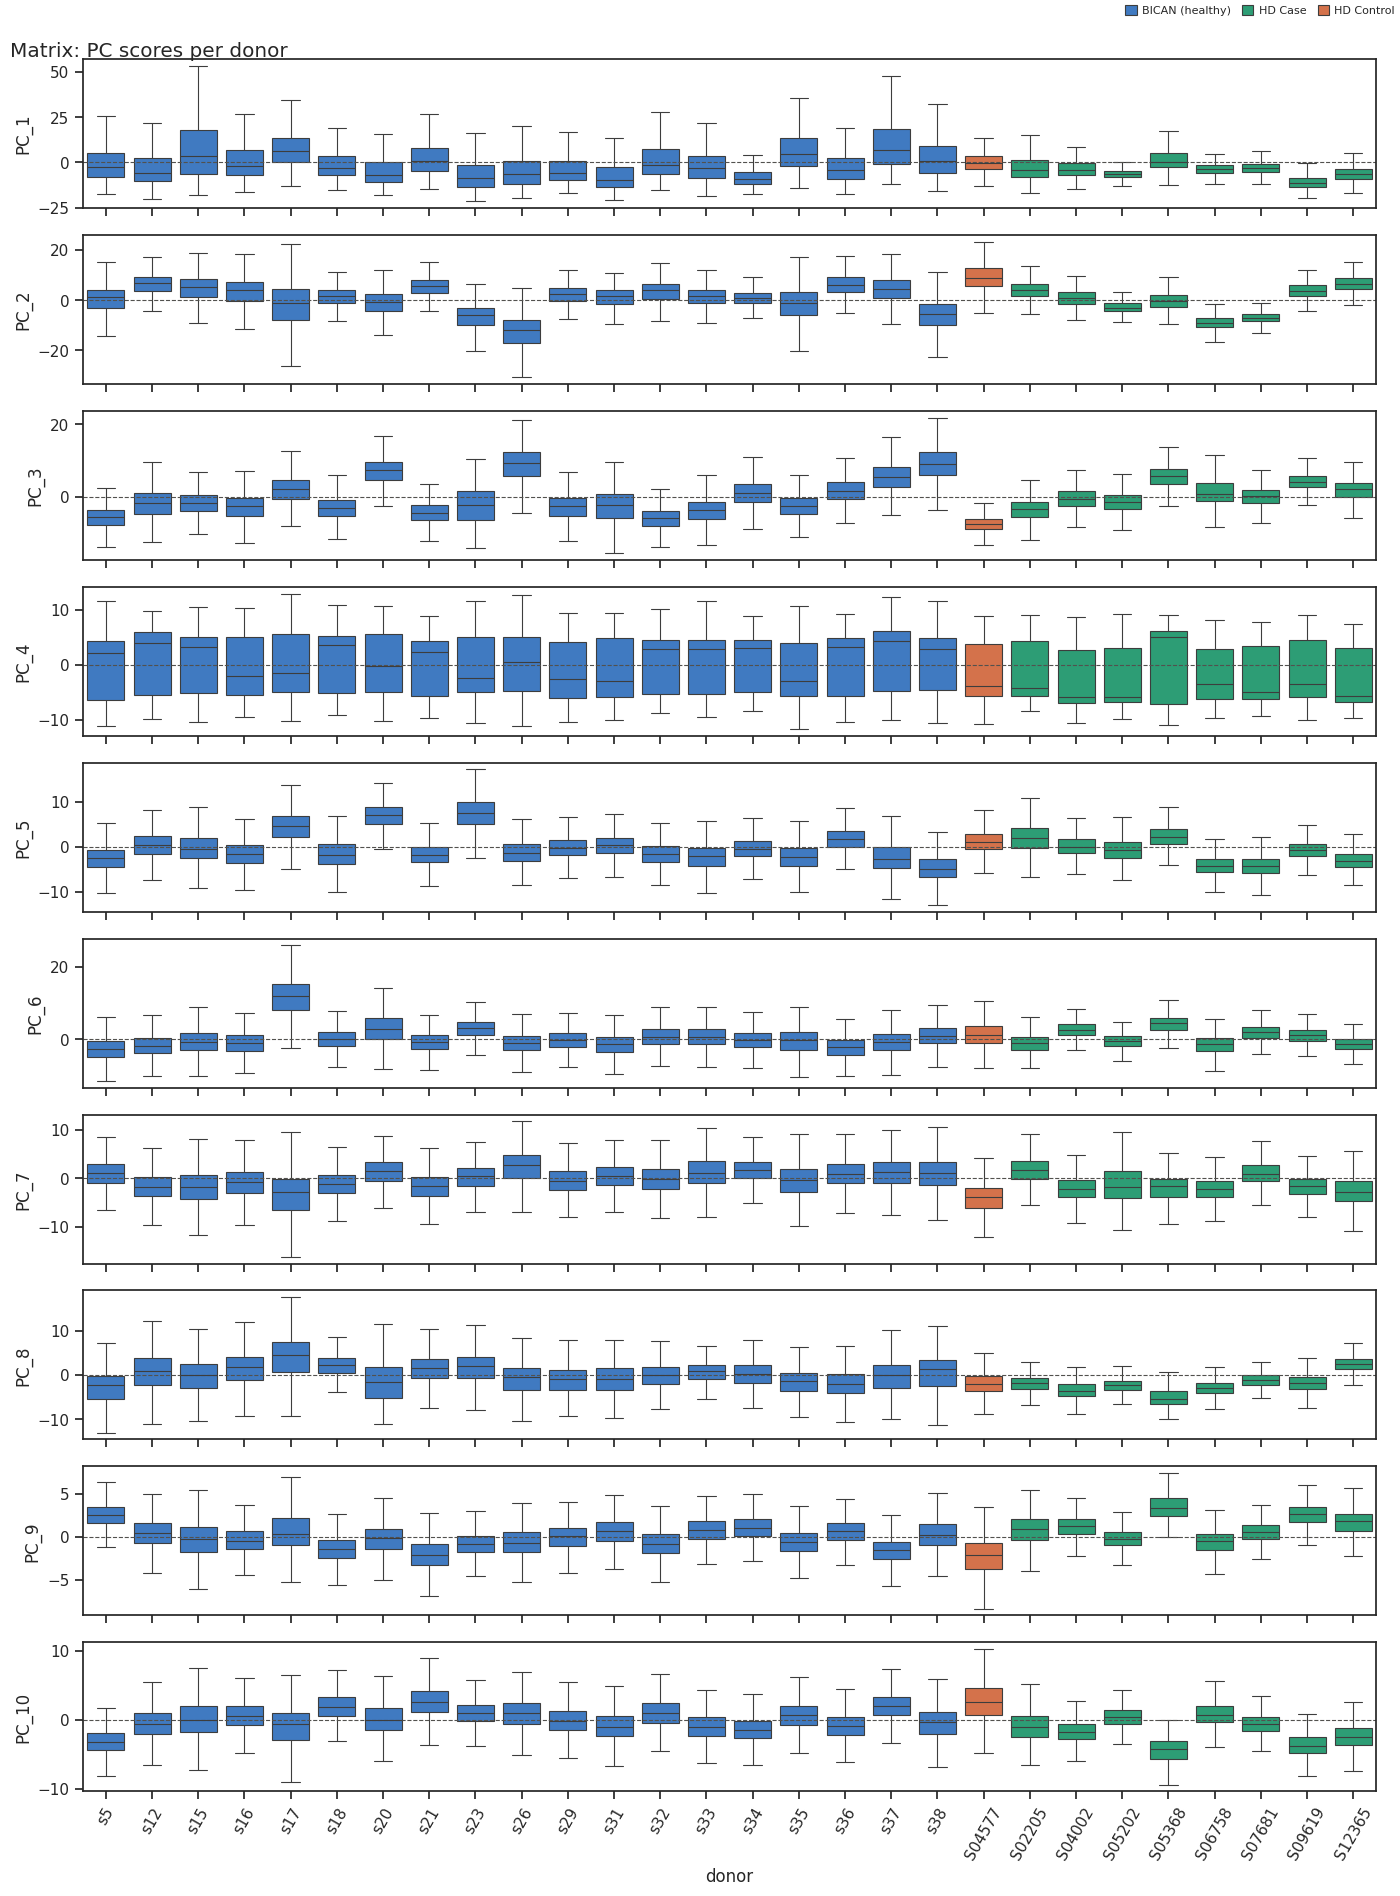

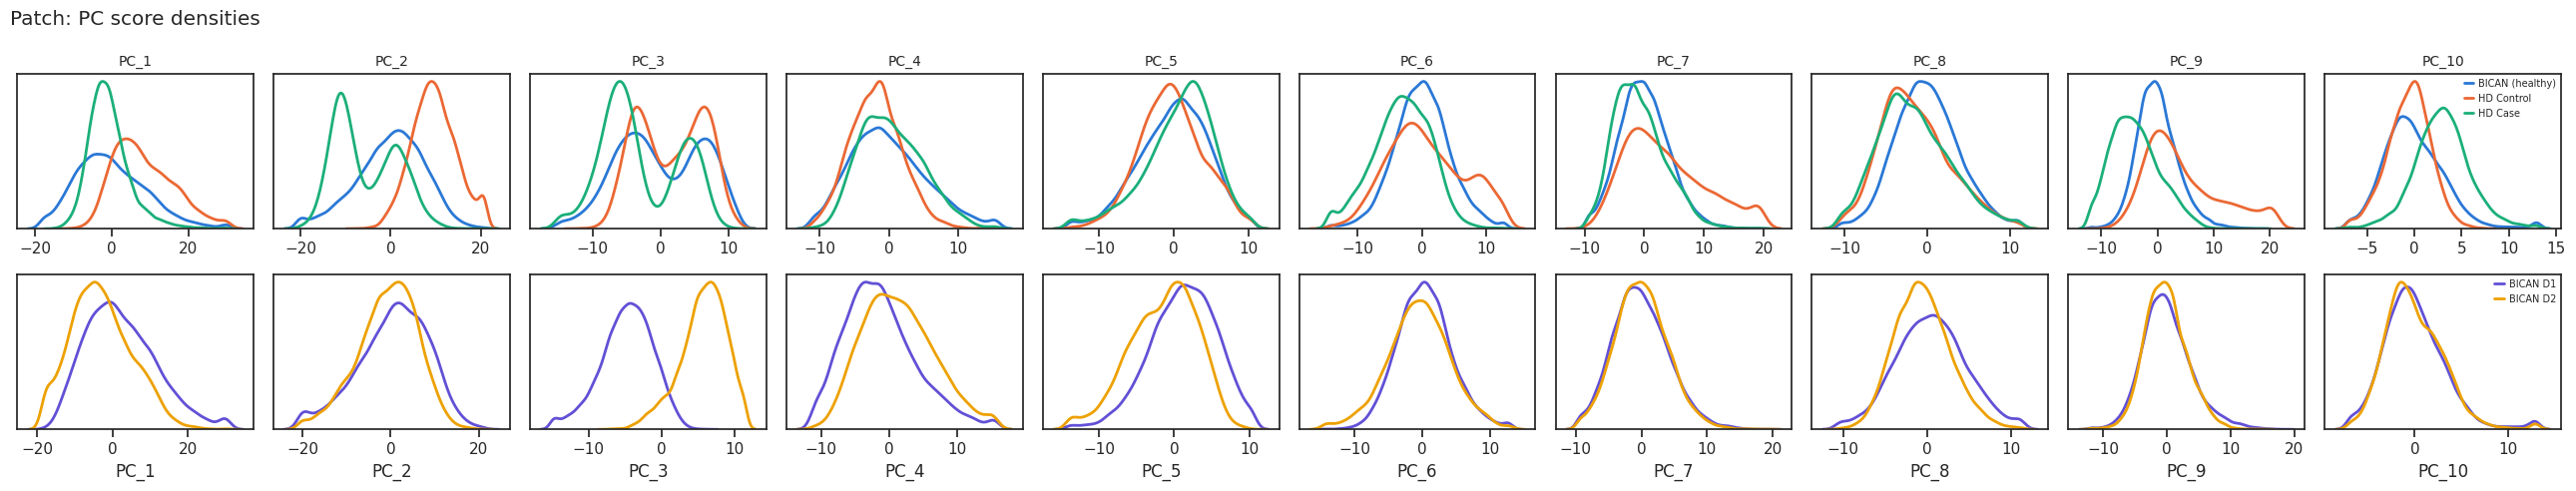

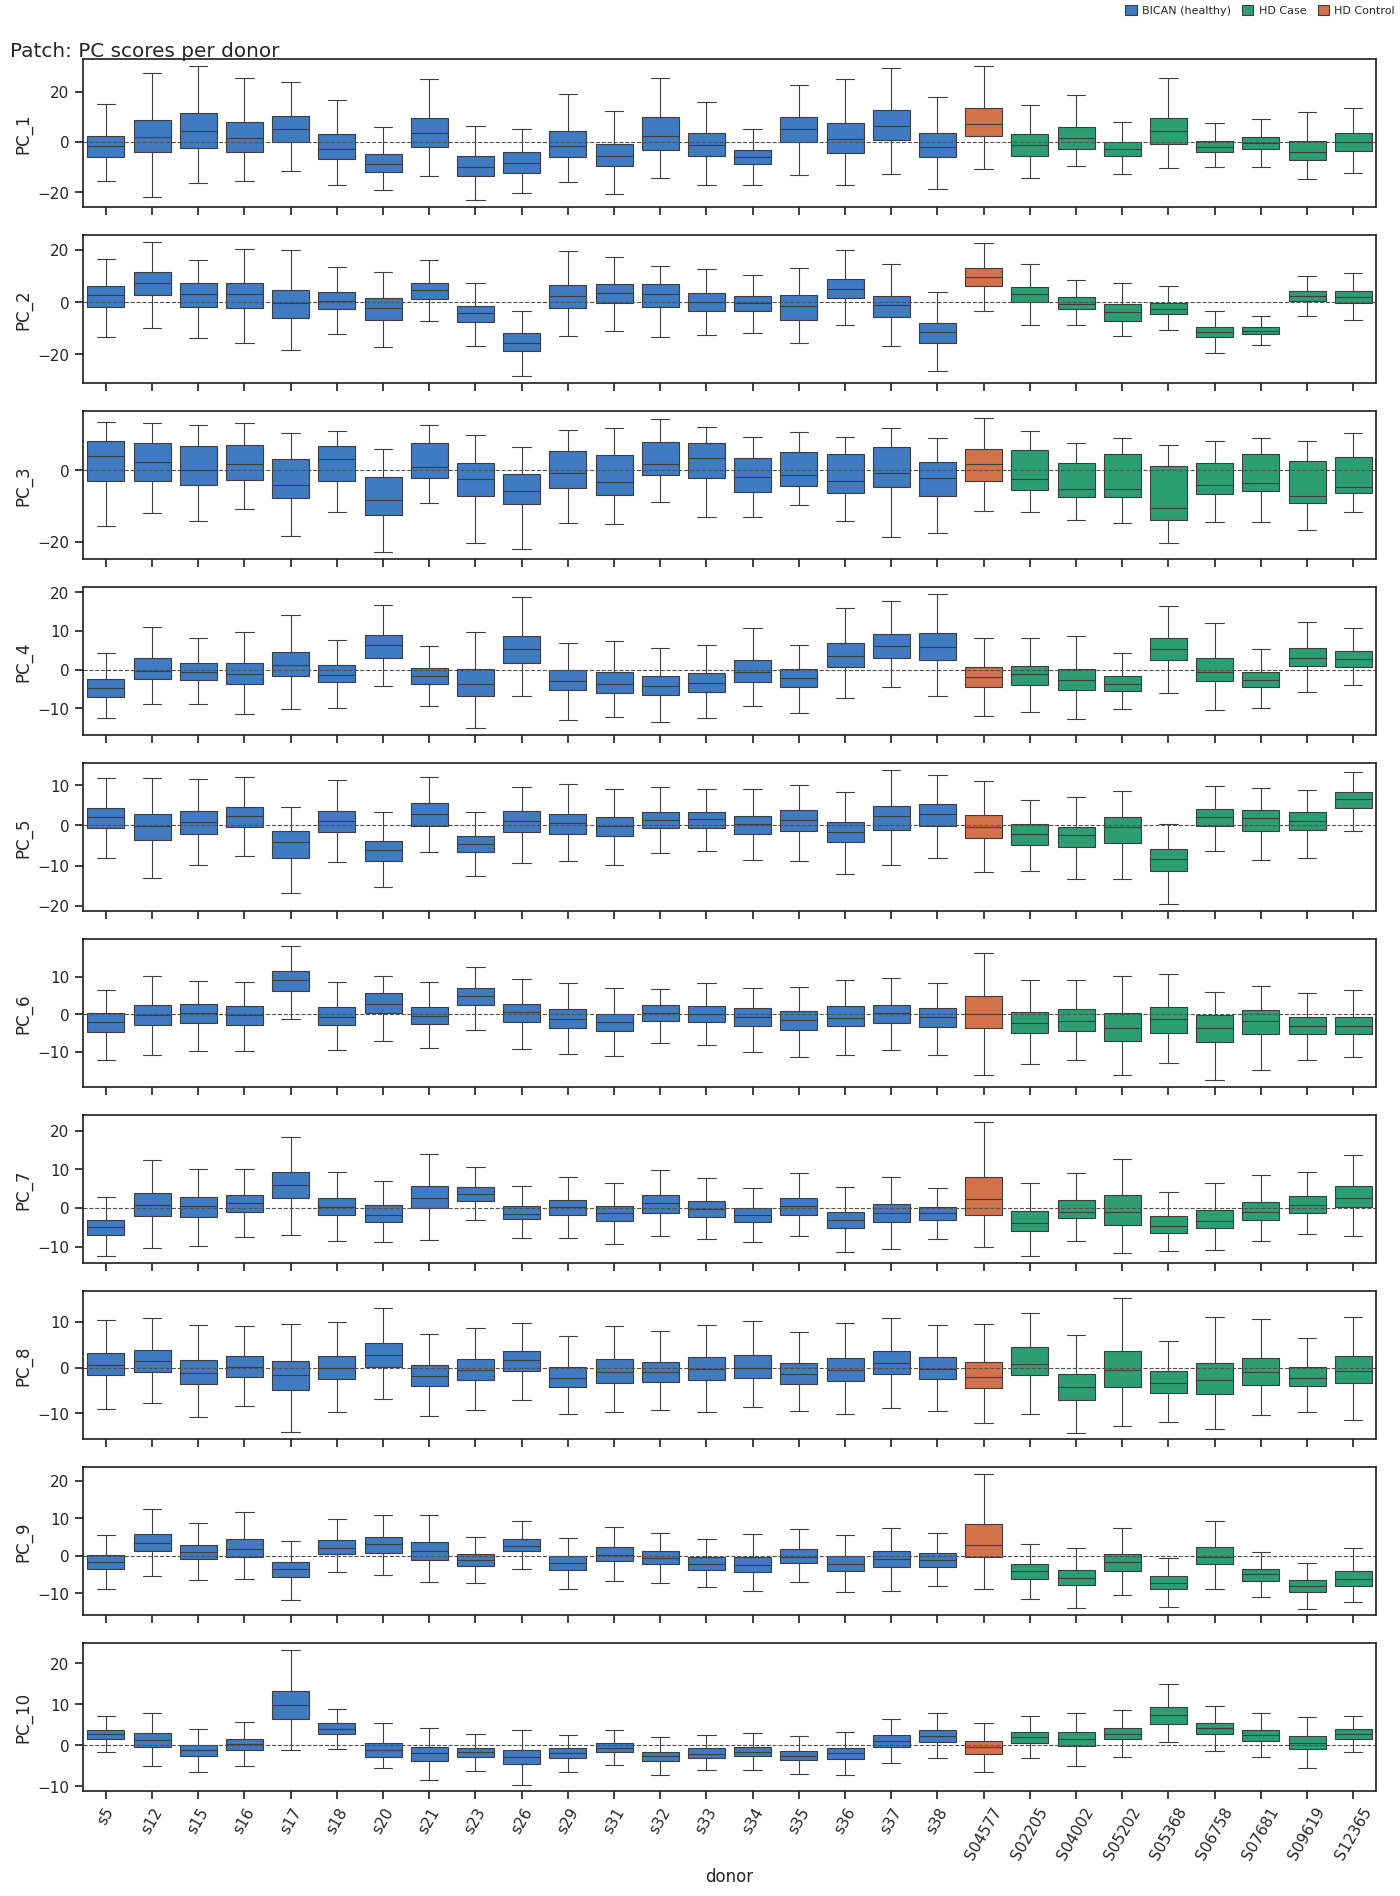

In [17]:
def plot_pc_distributions(ct, pcs):
    b = bican[ct].obs
    h = hd.obs[hd.obs["ct"] == ct]
    groups = {"BICAN (healthy)": b, "HD Control": h[h["Status"] == "Control"], "HD Case": h[h["Status"] == "Case"]}
    fig, axes = plt.subplots(2, len(pcs), figsize=(2.6 * len(pcs), 5), squeeze=False)
    for j, pc in enumerate(pcs):
        lo, hi = np.nanpercentile(np.r_[b[pc], h[pc]], [0.5, 99.5])
        for name, df in groups.items():
            sns.kdeplot(df[pc].clip(lo, hi), ax=axes[0, j], color=GROUP_COLORS[name], lw=2, label=name)
        for st, col in SUBTYPE_COLORS.items():
            sns.kdeplot(b.loc[b["msn_subtype"] == st, pc].clip(lo, hi), ax=axes[1, j], color=col, lw=2, label=f"BICAN {st}")
        for i in range(2):
            axes[i, j].set_yticks([])
            axes[i, j].set_ylabel("")
            axes[i, j].set_xlabel(pc if i == 1 else "")
        axes[0, j].set_title(pc, fontsize=10)
    axes[0, -1].legend(fontsize=7, loc="upper right")
    axes[1, -1].legend(fontsize=7, loc="upper right")
    fig.suptitle(f"{ct}: PC score densities", x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{ct}_pc_distributions.png", dpi=150)
    plt.show()


def plot_pc_by_donor(ct, pcs):
    b = bican[ct].obs[[*pcs, "donor_id"]].rename(columns={"donor_id": "donor"}).assign(group="BICAN (healthy)")
    h = hd.obs.loc[hd.obs["ct"] == ct, [*pcs, SAMPLE_VARIABLE, "Status"]].rename(columns={SAMPLE_VARIABLE: "donor"})
    h["group"] = "HD " + h.pop("Status")
    df = pd.concat([b, h])
    order = (sorted(b["donor"].unique(), key=lambda s: int(s[1:]))
             + sorted(h.loc[h["group"] == "HD Control", "donor"].unique())
             + sorted(h.loc[h["group"] == "HD Case", "donor"].unique()))
    fig, axes = plt.subplots(len(pcs), 1, figsize=(14, 1.9 * len(pcs)), sharex=True, squeeze=False)
    for ax, pc in zip(axes[:, 0], pcs):
        sns.boxplot(data=df, x="donor", y=pc, hue="group", order=order, palette=GROUP_COLORS,
                    showfliers=False, dodge=False, linewidth=0.8, ax=ax)
        ax.axhline(0, color="#52514e", lw=0.8, ls="--")
        ax.get_legend().remove()
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=3, fontsize=8)
    axes[-1, 0].tick_params(axis="x", rotation=60)
    fig.suptitle(f"{ct}: PC scores per donor", x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{ct}_pc_by_donor.png", dpi=150)
    plt.show()

for ct in CELL_TYPES:
    pcs = pca_ref[ct]["pcs"][:N_PCS_TO_PLOT]
    plot_pc_distributions(ct, pcs)
    plot_pc_by_donor(ct, pcs)

In [18]:
# Top-loading genes per PC (saved by calculate_pca) - helps naming what each axis is
for ct in CELL_TYPES:
    top = pd.read_csv(f"{PCA_REF_DIR}/{ct}/20_top_genes_per_pc.csv", index_col=0)
    print(f"\n######## {ct}: top 10 genes per PC (sign = loading direction)")
    rows = {}
    for pc in pca_ref[ct]["pcs"][:N_PCS_TO_PLOT]:
        rows[pc] = [f"{g}{'+' if l > 0 else '-'}" for g, l in zip(top[pc][:20], top[f"{pc}_loading"][:20])]
    display(pd.DataFrame(rows))


######## Matrix: top 10 genes per PC (sign = loading direction)


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10
0,PEG10+,NRGN+,MT-CO2+,DRD2+,WIPF3+,GULP1+,GPC5+,PCDH17+,HOXA13+,HOXA13+
1,ZNF385B-,PPP1R1B+,MT-ND2+,FOXP2-,SEMA6D+,PTCHD4+,PCDH9+,MAML2+,HOXC11+,TBX5-AS1+
2,PLCB1-,ARPP19+,MT-CO3+,FIG4+,ZNF385D-,HSPA1A+,DNAH14-,LSAMP-,TBX5-AS1+,HOXC11+
3,HSP90AB1+,MALAT1+,MT-CYB+,CNTNAP3B-,HSP90AA1+,CNTN3+,GDNF-AS1-,FAM163A+,HOXA6+,HOXA6+
4,CALM1+,CNR1+,MT-ND1+,PENK+,SHC3+,STXBP5L+,PREX2-,GRIN2A+,HOXA7+,HOXC10+
5,OPCML-,HPCA+,MT-ND4L+,RELN-,GAREM1+,CALCRL+,FCHSD2-,FSTL4+,HOXC10+,HOXD10+
6,PEA15+,GPR88+,MT-ND4+,CNTNAP4-,TMEM179+,BACH2-,KCNT2-,ADAM12-,HOXD10+,HOXA7+
7,NORAD+,PDE10A+,MT-ATP8+,DRD1-,ADCY1+,PCDH9+,SH3RF2+,ASTN2+,HOXD11+,HOXD11+
8,CTXN1+,SCN4B+,MT-CO1+,LINC01951-,SYT2-,GRM8+,NTNG1+,COL25A1+,HOXC13-AS+,HOXC13-AS+
9,VAMP2+,RGS9+,MT-ND5+,PTPRM+,MCTP2-,RPL37A+,TMC2-,HTR2A-,HOXB6+,HOXB6+



######## Patch: top 10 genes per PC (sign = loading direction)


,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10
0,CALM1+,CNR1+,DRD2+,MT-CO2+,NTM+,PCDH9+,RPL37A+,NTNG1+,PVT1+,XIST+
1,NNAT+,PDE10A+,FOXP2-,MT-CO1+,LINC02137+,FHOD3-,KIRREL3-,DCC-,RPL26+,HSPA1A+
2,NORAD+,SEMA6D+,FIG4+,MT-ND2+,BACH2-,KCNIP1-,RPL31+,MPDZ-,RPL31+,UTY-
3,VAMP2+,AK5-,CNTNAP4-,MT-CYB+,EPHB1+,KIRREL3+,UQCRB+,TIAM1-,TPT1+,USP9Y-
4,CALM3+,NRGN+,CHRM3+,MT-ND5+,GALNTL6-,BACH2-,DCC-,HS3ST5-,RPL37A+,TTTY14-
5,HSP90AB1+,ZNF83-,RELN-,MT-CO3+,DSCAM+,GRM1+,RPL26+,SEMA3D+,RPL34+,NLGN4Y-
6,BEX3+,ENC1+,PENK+,MT-ND1+,FAT1-,CNTN5-,RPL38+,MAML3+,RPL36A+,HSPA1B+
7,ACTG1+,GRM3+,GPR6+,MT-ND4L+,CNR1+,GRM8+,RPL36A+,KHDRBS2+,RPS24+,FOS+
8,PSAP+,GAREM1+,ADORA2A+,MT-ND4+,NPAS2-,DPP10+,EEF1A1+,SGCZ-,RPL38+,RASGEF1B+
9,TOMM20+,RGS6-,UTRN+,MT-ATP8+,PDE4B-,ZNF385D-,TPT1+,GRIK4+,UQCRB+,HSPB1+


# 9. Select PCs and define the final covariates

`SELECTED_PCS` (and `SENSITIVITY_PCS`) in the configuration cell decide which PCs enter the models. The cell below validates the choice, warns about flagged PCs, checks covariate collinearity on the actual design, and saves the selection next to the reference model hashes.

In [19]:
selection_record = dict(
    created=datetime.datetime.now().isoformat(timespec="seconds"),
    tested_term=TESTED_TERM,
    covariates=COVARIATES_FOR_DEG,
    models={m: v for m, v in MODELS.items()},
    pca_reference={ct: dict(created=pca_ref[ct]["meta"]["created"], sha256=pca_ref[ct]["meta"]["sha256"]) for ct in CELL_TYPES},
)
for model, sel in MODELS.items():
    for ct in CELL_TYPES:
        pcs = sel[ct]
        unknown = [pc for pc in pcs if pc not in pca_ref[ct]["pcs"]]
        assert not unknown, f"{model}/{ct}: {unknown} not in the reference model (only {N_PCS_REFERENCE} PCs saved)"
        if not pcs:
            continue
        d = diag[ct].loc[pcs]
        print(f"{model} / {ct}: {pcs}")
        for flag in ["donor_dominated", "subtype_axis", "repeat_associated"]:
            if d[flag].any():
                print(f"   ATTENTION: {flag}: {d.index[d[flag]].tolist()}")
        if (~d["transfers"]).any():
            print(f"   ATTENTION: poor transfer (var ratio outside {TRANSFER_VAR_RATIO_RANGE}): {d.index[~d['transfers']].tolist()}")
        print(f"   spatial: {d.index[d['spatial']].tolist()}")

with open(f"{OUT_ROOT}/selected_pcs.json", "w") as f:
    json.dump(selection_record, f, indent=2)

refPCs / Matrix: ['PC_1']
   ATTENTION: poor transfer (var ratio outside (0.25, 2.0)): ['PC_1']
   spatial: ['PC_1']
refPCs / Patch: ['PC_1']
   ATTENTION: repeat_associated: ['PC_1']
   spatial: ['PC_1']
refPCs_sensitivity / Matrix: ['PC_1', 'PC_6', 'PC_8']
   ATTENTION: poor transfer (var ratio outside (0.25, 2.0)): ['PC_1']
   spatial: ['PC_1', 'PC_6', 'PC_8']
refPCs_sensitivity / Patch: ['PC_1', 'PC_5', 'PC_12']
   ATTENTION: repeat_associated: ['PC_1']
   spatial: ['PC_1', 'PC_5', 'PC_12']



######################
Matrix
######################
ATTENTION: .X must be raw!


Retained donors : 8
Filtered genes  : 36943 -> 22495 (min_cells=80, min_counts=50)
5041 cells, 22495 genes, donors: {'S06758': 1748, 'S12365': 1207, 'S07681': 615, 'S05202': 600, 'S02205': 379, 'S09619': 320, 'S04002': 106, 'S05368': 66}

--- baseline: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + total_counts


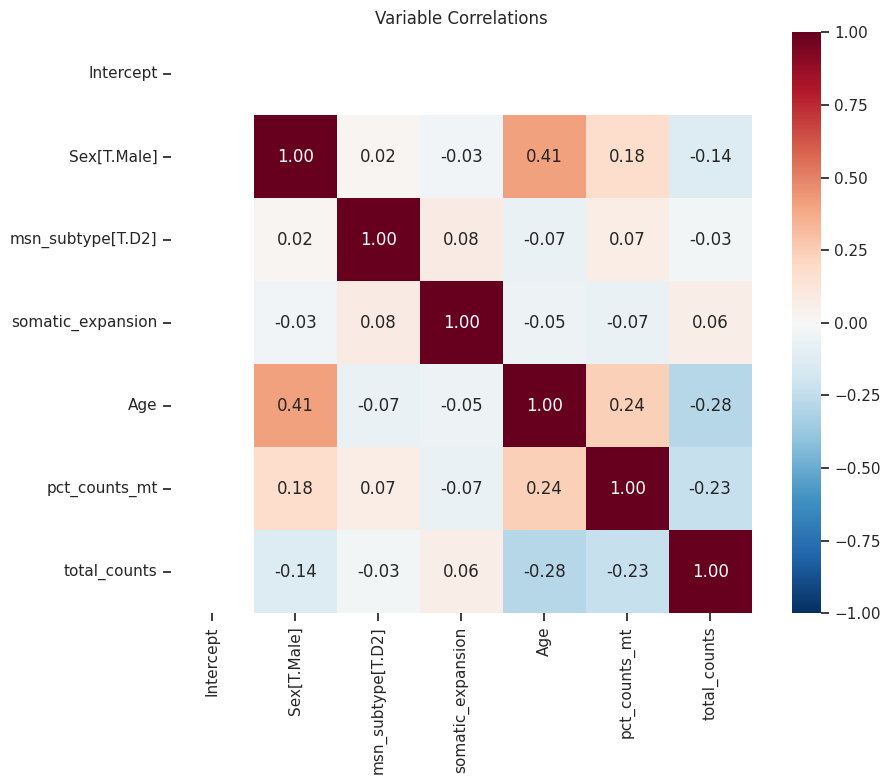

            variable       VIF
0          Intercept  7.530693
4                Age  1.318348
1        Sex[T.Male]  1.212213
6       total_counts  1.123857
5      pct_counts_mt  1.111981
2  msn_subtype[T.D2]  1.024056
3  somatic_expansion  1.015127

binary identifiability test. False

--- refPCs: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + total_counts


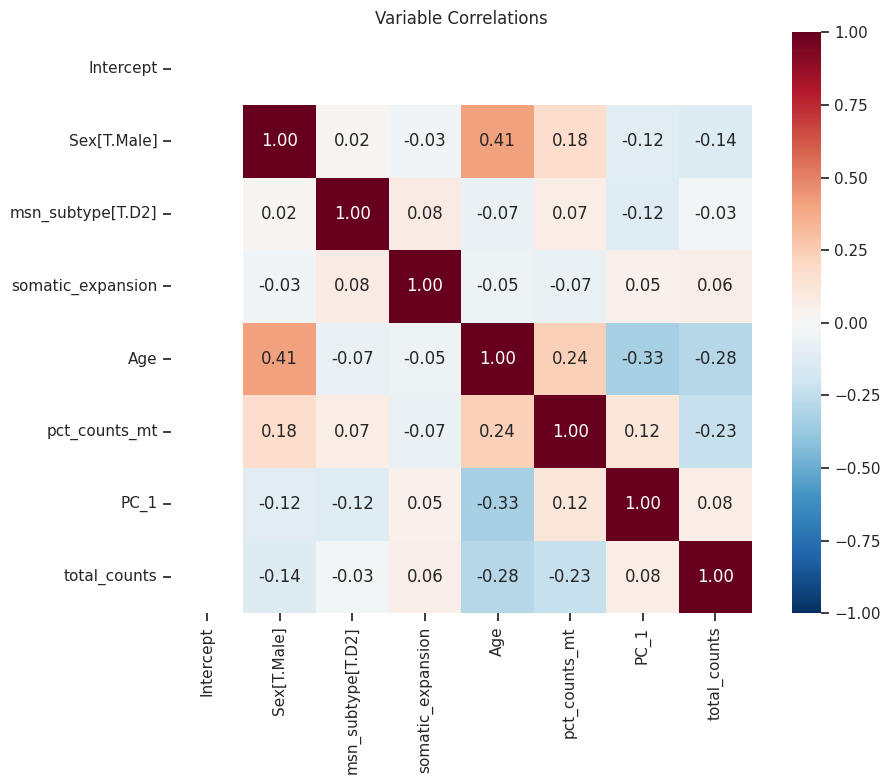

            variable       VIF
0          Intercept  7.531457
4                Age  1.508641
6               PC_1  1.221381
1        Sex[T.Male]  1.212299
5      pct_counts_mt  1.179132
7       total_counts  1.123979
2  msn_subtype[T.D2]  1.057853
3  somatic_expansion  1.019069

binary identifiability test. False

--- refPCs_sensitivity: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + PC_6 + PC_8 + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + PC_6 + PC_8 + total_counts


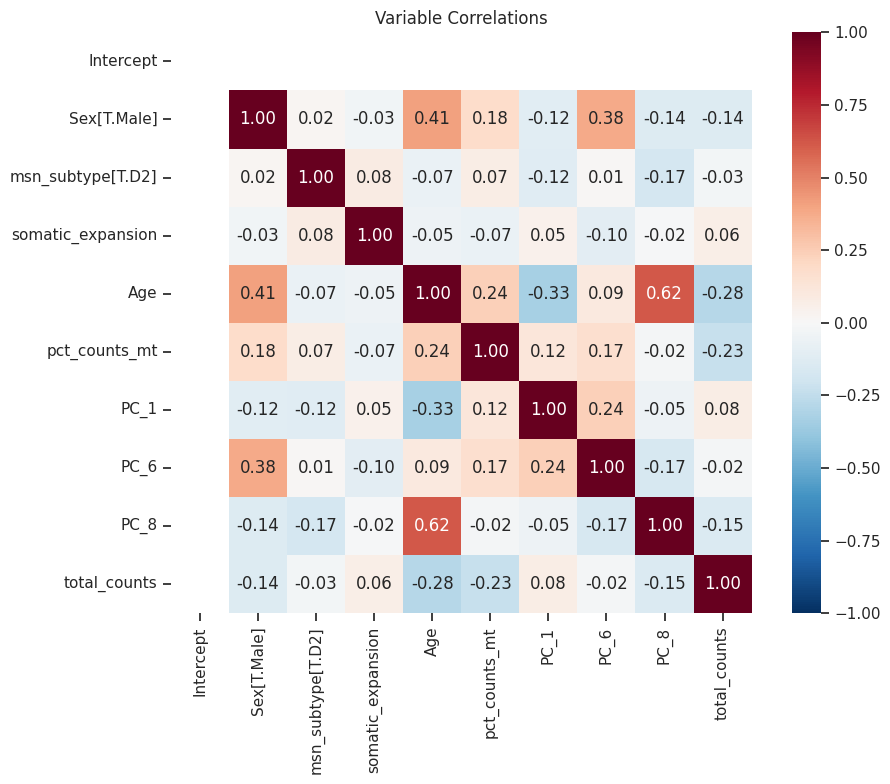

            variable       VIF
0          Intercept  7.958706
4                Age  3.866302
8               PC_8  2.827505
1        Sex[T.Male]  1.865440
6               PC_1  1.520846
7               PC_6  1.375984
5      pct_counts_mt  1.266682
9       total_counts  1.126347
2  msn_subtype[T.D2]  1.070639
3  somatic_expansion  1.034527

binary identifiability test. False

######################
Patch
######################
ATTENTION: .X must be raw!
Retained donors : 8
Filtered genes  : 36943 -> 16022 (min_cells=80, min_counts=50)
954 cells, 16022 genes, donors: {'S06758': 456, 'S12365': 182, 'S07681': 89, 'S05202': 67, 'S02205': 51, 'S09619': 51, 'S05368': 43, 'S04002': 15}

--- baseline: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + total_counts


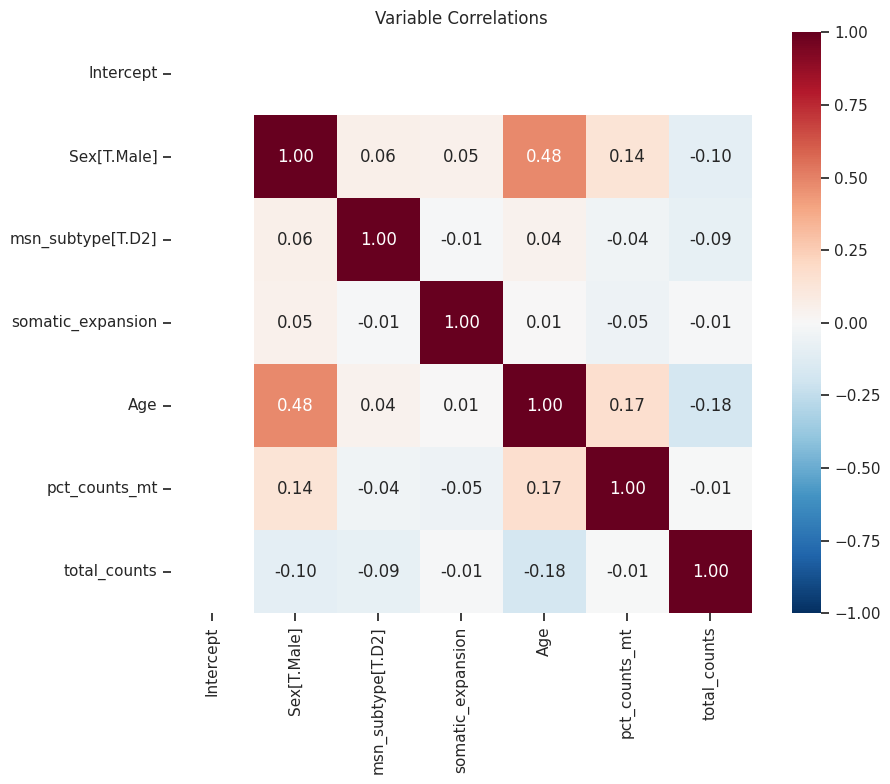

            variable       VIF
0          Intercept  7.036708
4                Age  1.354528
1        Sex[T.Male]  1.317958
5      pct_counts_mt  1.041195
6       total_counts  1.040172
2  msn_subtype[T.D2]  1.012671
3  somatic_expansion  1.007075

binary identifiability test. False

--- refPCs: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + total_counts


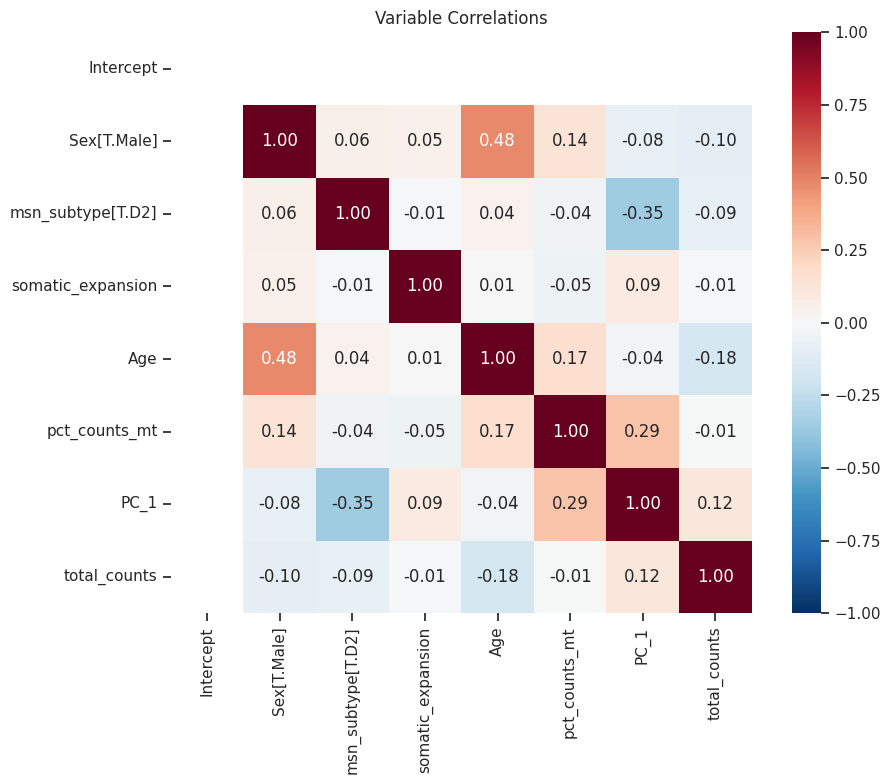

            variable       VIF
0          Intercept  7.036710
4                Age  1.354926
1        Sex[T.Male]  1.328473
6               PC_1  1.292288
5      pct_counts_mt  1.153339
2  msn_subtype[T.D2]  1.150813
7       total_counts  1.048136
3  somatic_expansion  1.021120

binary identifiability test. False

--- refPCs_sensitivity: ~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + PC_5 + PC_12 + (1|DONOR), offset total_counts
~ somatic_expansion + Age + Sex + pct_counts_mt + msn_subtype + PC_1 + PC_5 + PC_12 + total_counts


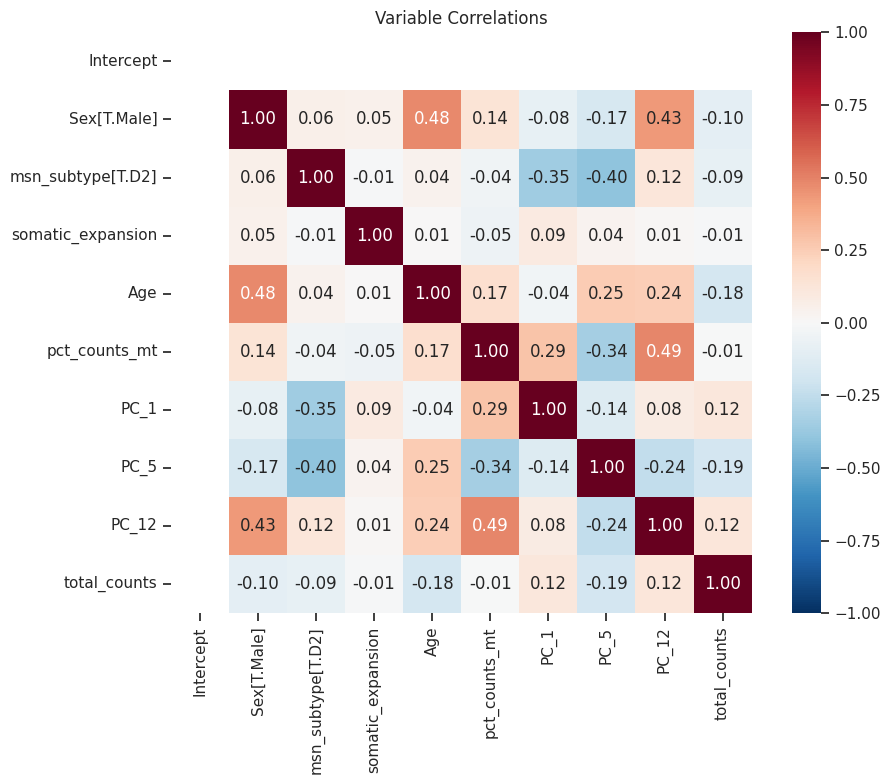

            variable       VIF
0          Intercept  9.361738
7               PC_5  2.252121
1        Sex[T.Male]  1.907598
4                Age  1.825867
5      pct_counts_mt  1.789910
2  msn_subtype[T.D2]  1.788442
8              PC_12  1.739113
6               PC_1  1.402081
9       total_counts  1.165710
3  somatic_expansion  1.026249

binary identifiability test. False


In [20]:
NUMERIC_TO_STANDARDISE = ["Age", "pct_counts_mt"]   # + PCs; the tested term stays in log2 units

def prepare_ct(ct):
    """Analysis cells of one cell type, with genes filtered exactly as in the original pipeline."""
    a = hd[hd.obs["in_analysis"] & (hd.obs["ct"] == ct)].copy()
    a.X = a.layers["counts"].copy()
    a = nebula_utils.filter_genes_for_nebula(a, SAMPLE_VARIABLE, "Status",
                                             min_cells_per_sample=MIN_CELLS_PER_DONOR, min_counts=50)
    n_donors = a.obs[SAMPLE_VARIABLE].nunique()
    assert n_donors >= MIN_DONORS, f"{ct}: only {n_donors} donors"
    assert a.n_vars > MIN_NUMBER_GENES_PER_ANALYSIS, f"{ct}: only {a.n_vars} genes after filtering"

    # Every model of this ct uses these same cells and genes. Continuous nuisance covariates are
    # z-scored for NEBULA's numerical stability (does not change the test of the tested term).
    pcs_any = sorted({pc for sel in MODELS.values() for pc in sel[ct]}, key=lambda s: int(s.split("_")[1]))
    for c in [*NUMERIC_TO_STANDARDISE, *pcs_any]:
        a.obs[c] = (a.obs[c] - a.obs[c].mean()) / a.obs[c].std()
    return a


def model_covariates(ct, adata_ct, pcs):
    covs = [TESTED_TERM, *COVARIATES_FOR_DEG, *pcs]
    missing = [c for c in covs if c not in adata_ct.obs.columns]
    assert not missing, f"missing covariates: {missing}"
    nan = adata_ct.obs[covs].isna().sum()
    assert nan.sum() == 0, f"NaN covariates: {nan[nan > 0].to_dict()}"
    single = [c for c in covs if adata_ct.obs[c].nunique() < 2]
    if single:
        print(f"ATTENTION: dropping single-valued covariates {single}")
        covs = [c for c in covs if c not in single]
    return covs


adata_by_ct = {}
for ct in CELL_TYPES:
    print(f"\n######################\n{ct}\n######################")
    adata_by_ct[ct] = prepare_ct(ct)
    a = adata_by_ct[ct]
    print(f"{a.n_obs} cells, {a.n_vars} genes, donors: {a.obs[SAMPLE_VARIABLE].value_counts().to_dict()}")
    for model, sel in MODELS.items():
        covs = model_covariates(ct, a, sel[ct])
        print(f"\n--- {model}: ~ {' + '.join(covs)} + (1|{SAMPLE_VARIABLE}), offset {LIBRARY_SIZE_COL}")
        os.makedirs(f"{OUT_ROOT}/{model}/{ct}", exist_ok=True)
        DEG.check_corr_cov_in_design(a, vars_in_formula=[*covs, LIBRARY_SIZE_COL], corr_thr=0.7,
                                     save_path=f"{OUT_ROOT}/{model}/{ct}/covariate_correlation_matrix.png")

# 10. Run NEBULA (Matrix and Patch separately)

Same machinery as `nebula_utils.run_nebula_with_factors`: counts → Seurat `.qs` via `preprocessing` → `run-nebula-parallel.sh` (NEBULA-LN, offset `total_counts`, random intercept per `DONOR`). The tested term is numeric, so no factor re-levelling is applied.

Each result CSV keeps NEBULA's `convergence` code. `fdr_somatic_expansion` is BH-adjusted over genes with `convergence ∈ CONVERGENCE_OK` and is NaN for the rest. A failed model is logged and skipped; it does not stop the loop.

In [21]:
def run_repeat_nebula(adata_ct, covs, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    qs_path = f"{out_dir}/tmp_for_nebula.qs"
    # remove stale chunks/results from a previous (failed) run with different covariates
    for stale in [f"{os.path.splitext(qs_path)[0]}__nebula_ln", f"{out_dir}/de_results"]:
        if os.path.exists(stale):
            shutil.rmtree(stale)

    obs = adata_ct.obs[[SAMPLE_VARIABLE, LIBRARY_SIZE_COL, *covs]].copy()
    for c in obs.columns:
        if not pd.api.types.is_numeric_dtype(obs[c]):
            obs[c] = obs[c].astype(str)
    b = ad.AnnData(X=adata_ct.layers["counts"].copy(), obs=obs, var=pd.DataFrame(index=adata_ct.var_names))

    tmp_dir = tempfile.mkdtemp(dir="/tmp")
    try:
        preprocessing.save_files_for_R_conversion(b, tmp_dir)
        preprocessing.build_qs_from_python_files(tmp_dir, saving_path=qs_path)   # no relevel: tested term is numeric
    finally:
        shutil.rmtree(tmp_dir, ignore_errors=True)

    res_qs = DEG.run_nebula_parallel_script(
        path_qs=qs_path, path_nebula_script=PARALLEL_NEBULA_SCRIPT_PATH,
        id_col=SAMPLE_VARIABLE, covs=covs, offset_col=LIBRARY_SIZE_COL,
        n_folds=NEBULA_N_FOLDS, n_cores=NEBULA_N_CORES, save_tmp=False, suffix=None,
    )
    csv_path = f"{out_dir}/deg_results.csv"
    ro.r(f"""
        suppressMessages(library(qs))
        obj <- qread("{res_qs}")
        df <- obj$summary
        if (length(obj$convergence) == nrow(df)) df$convergence <- obj$convergence
        write.csv(df, "{csv_path}", row.names = FALSE)
    """)
    os.remove(qs_path)
    shutil.rmtree(f"{out_dir}/de_results", ignore_errors=True)

    df = pd.read_csv(csv_path)
    for col in [f"logFC_{TESTED_TERM}", f"p_{TESTED_TERM}", "gene", "convergence"]:
        assert col in df.columns, f"{col} missing from NEBULA output"
    ok = df["convergence"].isin(CONVERGENCE_OK) & df[f"p_{TESTED_TERM}"].notna()
    df[f"fdr_{TESTED_TERM}"] = np.nan
    df.loc[ok, f"fdr_{TESTED_TERM}"] = multipletests(df.loc[ok, f"p_{TESTED_TERM}"], method="fdr_bh")[1]
    df.to_csv(csv_path, index=False)
    return df


run_log = []
if RUN_NEBULA:
    for ct in CELL_TYPES:
        a = adata_by_ct[ct]
        for model, sel in MODELS.items():
            print(f"\n\n######################\n{model} / {ct}\n######################\n")
            out_dir = f"{OUT_ROOT}/{model}/{ct}"
            covs = model_covariates(ct, a, sel[ct])
            entry = dict(model=model, ct=ct, covariates=covs, n_cells=int(a.n_obs), n_genes=int(a.n_vars),
                         donors=a.obs[SAMPLE_VARIABLE].value_counts().to_dict(),
                         started=datetime.datetime.now().isoformat(timespec="seconds"))
            try:
                df = run_repeat_nebula(a, covs, out_dir)
                conv = df["convergence"].value_counts().to_dict()
                entry.update(status="ok", convergence=conv,
                             frac_converged=float(df["convergence"].isin(CONVERGENCE_OK).mean()),
                             n_sig=int((df[f"fdr_{TESTED_TERM}"] < FDR_THR).sum()))
                print(f"{model}/{ct}: convergence codes {conv}; {entry['n_sig']} genes FDR < {FDR_THR}")
                if entry["frac_converged"] < 0.8:
                    print(f"ATTENTION: only {entry['frac_converged']:.0%} genes converged")
            except Exception as e:
                entry.update(status=f"failed: {e}")
                print(f"ERROR: {model}/{ct} failed: {e}")
            with open(f"{out_dir}/run_config.json", "w") as f:
                json.dump({**entry, "pca_reference": selection_record["pca_reference"].get(ct)}, f, indent=2, default=str)
            run_log.append(entry)
    display(pd.DataFrame(run_log)[["model", "ct", "status", "n_cells", "n_genes", "frac_converged", "n_sig"]])
else:
    print("RUN_NEBULA = False -> skipping (Section 11 reads any results already on disk)")



######################
baseline / Matrix
######################



2026-10-29 18:40:56 | [WARNING] R callback write-console: Loading required package: SeuratObject
  
2026-10-29 18:40:56 | [WARNING] R callback write-console: Loading required package: sp
  
2026-10-29 18:40:57 | [WARNING] R callback write-console: 
Attaching package: ‘SeuratObject’

  
2026-10-29 18:40:57 | [WARNING] R callback write-console: The following objects are masked from ‘package:base’:

    %||%, intersect, t

  



    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

2026-10-29 18:41:00 | [WARNING] R callback write-console: 
Attaching package: ‘Seurat’

  
2026-10-29 18:41:00 | [WARNING] R callback write-console: The following object is masked from ‘package:base’:

    %||%

  
2026-10-29 18:41:00 | [WARNING] R callback write-console: qs 0.27.3. Announcement: https://github.com/qsbase/qs/issues/103
  


[1] "Creating Seurat object..."


2026-10-29 18:41:19 | [WARNING] R callback write-console: Warning:  
2026-10-29 18:41:19 | [WARNING] R callback write-console:  Feature names cannot have underscores ('_'), replacing with dashes ('-')
  
2026-10-29 18:41:19 | [WARNING] R callback write-console: Warning:  
2026-10-29 18:41:19 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


... (8 outputs left out)

[1] "Saving Seurat object as .qs..."
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs/Patch/tmp_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs/Patch/tmp_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs/Patch/tmp_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0 --covs somatic_expansion,Age,Sex,pct_counts_mt,msn_subtype,PC_1
[INFO] Input: /home/gdallagl/

2026-10-29 18:48:30 | [WARNING] R callback write-console: Warning:  
2026-10-29 18:48:30 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs_sensitivity/Patch/tmp_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs_sensitivity/Patch/tmp_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula/refPCs_sensitivity/Patch/tmp_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0 --covs somatic_expansion,Age,Sex,pct_counts_mt,msn_subtyp

,model,ct,status,n_cells,n_genes,frac_converged,n_sig
0,baseline,Matrix,ok,5041,22495,0.977195,1257
1,refPCs,Matrix,ok,5041,22495,0.978351,1084
2,refPCs_sensitivity,Matrix,ok,5041,22495,0.978884,1129
3,baseline,Patch,ok,954,16022,0.985832,966
4,refPCs,Patch,ok,954,16022,0.983647,762
5,refPCs_sensitivity,Patch,ok,954,16022,0.987330,719


# 11. Robustness: baseline vs healthy-reference PCs, and outputs

* **Agreement of effects.** Correlation of `logFC_somatic_expansion` and of z = logFC/se between models, plus overlap of significant genes. If repeat-associated DEGs are robust to healthy expression structure, they should survive the PC adjustment with similar effect sizes.
* **Positive control.** Handsaker et al. phase C+ / C− genes, i.e. genes that change gradually with CAG length in MSNs. Reported: the fraction with the expected sign (C+ up, C− down per doubling of CAG) and the number significant in that direction. If adding PCs sharply reduces this concordance, the PCs are absorbing real repeat-driven biology (reading (b) in Section 8). *Caveat:* those lists were derived from Handsaker data that overlaps these donors, so this is a consistency check, not independent validation.

In [22]:
results = {}
for model in MODELS:
    for ct in CELL_TYPES:
        p = f"{OUT_ROOT}/{model}/{ct}/deg_results.csv"
        if os.path.exists(p):
            results[(model, ct)] = pd.read_csv(p).set_index("gene")
print("available:", list(results))

lfc, se, pcol, fdr = (f"logFC_{TESTED_TERM}", f"se_{TESTED_TERM}", f"p_{TESTED_TERM}", f"fdr_{TESTED_TERM}")

summary = []
for (model, ct), df in results.items():
    conv = df["convergence"].isin(CONVERGENCE_OK)
    sig = df[fdr] < FDR_THR
    summary.append(dict(model=model, ct=ct, n_genes=len(df), n_converged=int(conv.sum()),
                        n_sig=int(sig.sum()), n_up=int((sig & (df[lfc] > 0)).sum()), n_down=int((sig & (df[lfc] < 0)).sum()),
                        p_hist_lt_0_05=float((df.loc[conv, pcol] < 0.05).mean())))
summary = pd.DataFrame(summary)
display(summary)
summary.to_csv(f"{OUT_ROOT}/summary_n_degs.csv", index=False)

available: [('baseline', 'Matrix'), ('baseline', 'Patch'), ('refPCs', 'Matrix'), ('refPCs', 'Patch'), ('refPCs_sensitivity', 'Matrix'), ('refPCs_sensitivity', 'Patch')]


,model,ct,n_genes,n_converged,n_sig,n_up,n_down,p_hist_lt_0_05
0,baseline,Matrix,22495,21982,1257,994,263,0.185970
1,baseline,Patch,16022,15795,966,755,211,0.196455
2,refPCs,Matrix,22495,22008,1084,839,245,0.168348
3,refPCs,Patch,16022,15760,762,578,184,0.176459
4,refPCs_sensitivity,Matrix,22495,22020,1129,872,257,0.170663
5,refPCs_sensitivity,Patch,16022,15819,719,527,192,0.172893


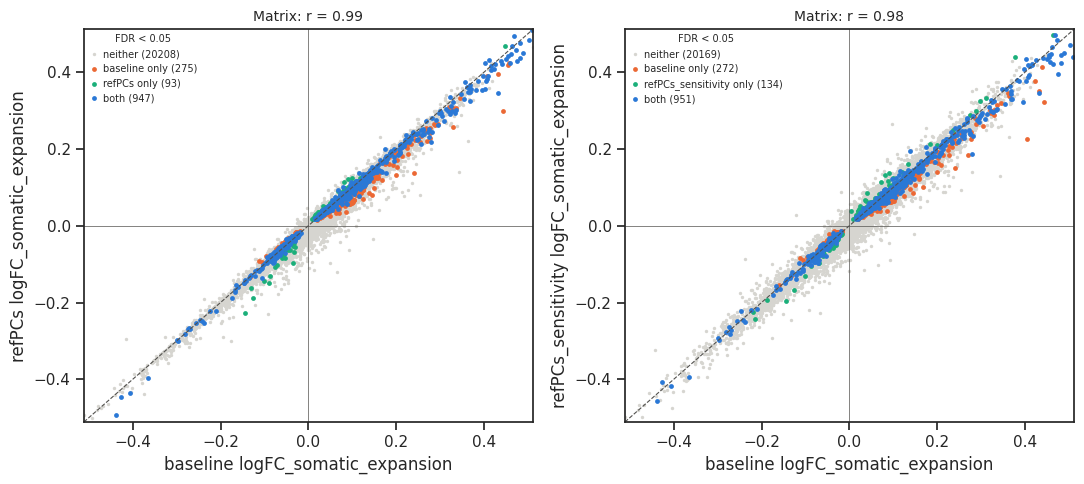

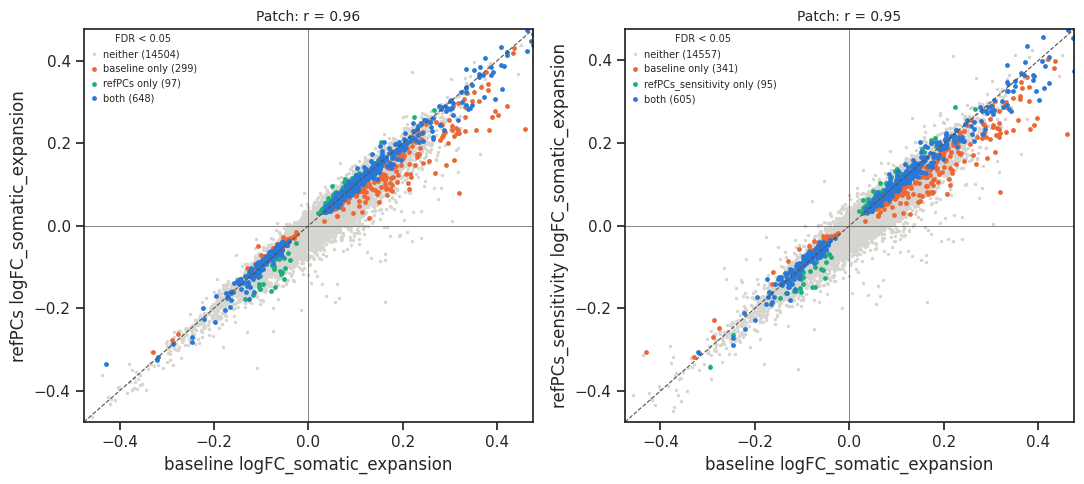

,ct,model,n_genes,pearson_logFC,spearman_z,slope_logFC,n_sig_baseline,n_sig_model,n_sig_both,jaccard,frac_baseline_sig_kept
0,Matrix,refPCs,21523,0.989,0.978,0.973,1222,1040,947,0.720,0.775
1,Matrix,refPCs_sensitivity,21526,0.984,0.976,0.970,1223,1085,951,0.701,0.778
2,Patch,refPCs,15548,0.959,0.952,0.931,947,745,648,0.621,0.684
3,Patch,refPCs_sensitivity,15598,0.955,0.950,0.925,946,700,605,0.581,0.640


In [23]:
comp_rows = []
for ct in CELL_TYPES:
    if ("baseline", ct) not in results:
        continue
    others = [m for m in MODELS if m != "baseline" and (m, ct) in results]
    if not others:
        continue
    fig, axes = plt.subplots(1, len(others), figsize=(5.5 * len(others), 5), squeeze=False)
    for ax, model in zip(axes[0], others):
        b0 = results[("baseline", ct)]
        b1 = results[(model, ct)]
        g = b0.index.intersection(b1.index)
        ok = b0.loc[g, "convergence"].isin(CONVERGENCE_OK) & b1.loc[g, "convergence"].isin(CONVERGENCE_OK)
        g = g[ok.values]
        s0, s1 = b0.loc[g, fdr] < FDR_THR, b1.loc[g, fdr] < FDR_THR
        z0, z1 = b0.loc[g, lfc] / b0.loc[g, se], b1.loc[g, lfc] / b1.loc[g, se]
        n_union = int((s0 | s1).sum())
        comp_rows.append(dict(
            ct=ct, model=model, n_genes=len(g),
            pearson_logFC=np.corrcoef(b0.loc[g, lfc], b1.loc[g, lfc])[0, 1],
            spearman_z=stats.spearmanr(z0, z1)[0],
            slope_logFC=np.polyfit(b0.loc[g, lfc], b1.loc[g, lfc], 1)[0],
            n_sig_baseline=int(s0.sum()), n_sig_model=int(s1.sum()), n_sig_both=int((s0 & s1).sum()),
            jaccard=(s0 & s1).sum() / n_union if n_union else np.nan,
            frac_baseline_sig_kept=(s0 & s1).sum() / s0.sum() if s0.sum() else np.nan,
        ))
        cat = np.select([s0 & s1, s0 & ~s1, ~s0 & s1], ["both", "baseline only", f"{model} only"], "neither")
        palette = {"neither": "#d6d5d0", "both": "#2a78d6", "baseline only": "#eb6834", f"{model} only": "#1baf7a"}
        for c in ["neither", "baseline only", f"{model} only", "both"]:
            m = cat == c
            ax.scatter(b0.loc[g, lfc][m], b1.loc[g, lfc][m], s=6 if c == "neither" else 12, c=palette[c],
                       linewidths=0, label=f"{c} ({m.sum()})", rasterized=True)
        lim = np.nanpercentile(np.abs(np.r_[b0.loc[g, lfc], b1.loc[g, lfc]]), 99.9)
        ax.plot([-lim, lim], [-lim, lim], color="#52514e", lw=0.8, ls="--")
        ax.axhline(0, color="#52514e", lw=0.5); ax.axvline(0, color="#52514e", lw=0.5)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.set_xlabel(f"baseline {lfc}"); ax.set_ylabel(f"{model} {lfc}")
        ax.set_title(f"{ct}: r = {comp_rows[-1]['pearson_logFC']:.2f}", fontsize=10)
        ax.legend(fontsize=7, title=f"FDR < {FDR_THR}", title_fontsize=7, loc="upper left")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{ct}_logFC_baseline_vs_PC_models.png", dpi=150)
    plt.show()

comparison = pd.DataFrame(comp_rows)
display(comparison.round(3))
comparison.to_csv(f"{OUT_ROOT}/comparison_baseline_vs_PC_models.csv", index=False)

In [24]:
# Positive control: Handsaker phase C genes (gradual CAG-length-dependent changes in MSNs)
phase_sets = {
    "C+": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_plus_genes.csv")["Gene"].astype(str), 1),
    "C-": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_minus_genes.csv")["Gene"].astype(str), -1),
    "D": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_d_genes.csv")["Gene"].astype(str), -1),
}
ctrl_rows = []
for (model, ct), df in results.items():
    df = df[df["convergence"].isin(CONVERGENCE_OK)]
    for name, (genes, sign) in phase_sets.items():
        d = df[df.index.isin(genes)]
        right = np.sign(d[lfc]) == sign
        ctrl_rows.append(dict(model=model, ct=ct, set=name, n_in_set=len(genes), n_tested=len(d),
                              frac_expected_sign=right.mean() if len(d) else np.nan,
                              n_sig_expected_sign=int(((d[fdr] < FDR_THR) & right).sum()),
                              n_sig_opposite_sign=int(((d[fdr] < FDR_THR) & ~right).sum()),
                              median_z=float((d[lfc] / d[se]).median()) if len(d) else np.nan))
handsaker_ctrl = pd.DataFrame(ctrl_rows)
if handsaker_ctrl.empty:
    print("No NEBULA results on disk yet -> nothing to compare")
else:
    display(handsaker_ctrl.pivot_table(index=["ct", "set"], columns="model",
                                       values=["frac_expected_sign", "n_sig_expected_sign", "median_z"]).round(3))
    handsaker_ctrl.to_csv(f"{OUT_ROOT}/handsaker_phaseC_concordance.csv", index=False)

frac_expected_sign                           median_z         \
model                baseline refPCs refPCs_sensitivity baseline refPCs   
ct     set                                                                
Matrix C+               0.996  0.996              0.996    3.576  3.635   
       C-               1.000  1.000              1.000   -4.379 -4.101   
       D                  NaN    NaN                NaN      NaN    NaN   
Patch  C+               0.992  0.989              0.985    3.126  2.930   
       C-               0.995  0.989              0.989   -4.146 -3.748   
       D                  NaN    NaN                NaN      NaN    NaN   

                              n_sig_expected_sign                            
model      refPCs_sensitivity            baseline refPCs refPCs_sensitivity  
ct     set                                                                   
Matrix C+               3.619               180.0  180.0              183.0  
       C-              -4.131               147.0  126.0              128.0  
       D                  NaN                 0.0    0.0                0.0  
Patch  C+               2.905               148.0  127.0              122.0  
       C-              -3.830               136.0  114.0              125.0  
       D                  NaN                 0.0    0.0                0.0

In [25]:
# cell-level design table actually used (no counts), for reproducibility / downstream plots
for ct, a in adata_by_ct.items():
    a.obs[[SAMPLE_VARIABLE, REPEAT_COL, "EXP_germline", "somatic_gain_CAG", TESTED_TERM, LIBRARY_SIZE_COL,
           *COVARIATES_FOR_DEG, *[pc for pc in pca_ref[ct]["pcs"] if pc in a.obs]]].to_csv(f"{OUT_ROOT}/design_table_{ct}.csv")

print("Outputs in", OUT_ROOT)
for p in sorted(glob.glob(f"{OUT_ROOT}/**/*", recursive=True)):
    if os.path.isfile(p) and "/hd_projection/" not in p:
        print("  ", os.path.relpath(p, OUT_ROOT))

Outputs in /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula
   Matrix_repeat_effect_position_decomposition.csv
   Patch_repeat_effect_position_decomposition.csv
   baseline/Matrix/covariate_correlation_matrix.png
   baseline/Matrix/deg_results.csv
   baseline/Matrix/run_config.json
   baseline/Patch/covariate_correlation_matrix.png
   baseline/Patch/deg_results.csv
   baseline/Patch/run_config.json
   comparison_baseline_vs_PC_models.csv
   design_table_Matrix.csv
   design_table_Patch.csv
   figures/Matrix_logFC_baseline_vs_PC_models.png
   figures/Matrix_pc_by_donor.png
   figures/Matrix_pc_diagnostics_heatmap.png
   figures/Matrix_pc_distributions.png
   figures/Matrix_repeat_effect_position_decomposition.png
   figures/Matrix_spatial_pcs_s23.png
   figures/Matrix_spatial_pcs_s38.png
   figures/Matrix_volcano_all_models.png
   figures/Patch_logFC_baseline_vs_PC_models.png
   figures/Patch_pc_by_donor.png
   figures/Patch_pc_diagnostics_heatmap.png
   figures/Patch_pc

# Vulcano

In [26]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import decoupler as dc
import statsmodels.formula.api as smf

from utils import DEG

RESULTS_ROOT = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/repeat_nebula"
MODELS       = ["baseline", "refPCs", "refPCs_sensitivity"]
CELL_TYPES   = ["Matrix", "Patch"]

TESTED_TERM = "somatic_expansion"
LOGFC_COL   = f"logFC_{TESTED_TERM}"      # converted below: ln -> log2 (per doubling of CAGLENGTH / EXP_germline)
SE_COL      = f"se_{TESTED_TERM}"
COL_P_ADJ   = f"fdr_{TESTED_TERM}"        # BH over converged genes, computed in Handsaker_DEG_repeats_refPCA.ipynb
GENE_COL    = "gene"
PVAL_THR    = 0.05
LOGFC_THR   = 0.25    # log2 FC per doubling of the expanded allele (a doubling is a big change: 42 -> 84 CAG)
REMOVE_GENE_TOO_HIGH_INTERCEPT = True    # same filter as Handsaker_DEG_interpretation.ipynb

# gene sets (same files as Handsaker_DEG_interpretation.ipynb)
df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv").set_index("gene")
phase_d       = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_d_genes.csv")
phase_c_plus  = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_plus_genes.csv")
phase_c_minus = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_minus_genes.csv")
categories_handsaker_phases = {
    "Phase D":  (phase_d.Gene.to_list(), "blue"),
    "Phase C+": (phase_c_plus.Gene.to_list(), "green"),
    "Phase C-": (phase_c_minus.Gene.to_list(), "cyan"),
}


def load_results(model, ct):
    """NEBULA output of one model, converged genes only, logFC in log2 units."""
    p = f"{RESULTS_ROOT}/{model}/{ct}/deg_results.csv"
    df = pd.read_csv(p)
    df = df[df[COL_P_ADJ].notna()].copy()                          # fdr is NaN for non-converged genes
    for c in [c for c in df.columns if c.startswith("logFC_") and c != "logFC_(Intercept)"]:
        df[c] = df[c] / np.log(2)                                   # ln -> log2
    for c in [c for c in df.columns if c.startswith("se_") and c != "se_(Intercept)"]:
        df[c] = df[c] / np.log(2)
    if REMOVE_GENE_TOO_HIGH_INTERCEPT:
        df = df[df["logFC_(Intercept)"] >= -20]                     # extremely lowly expressed genes
    df["z_score"] = df[LOGFC_COL] / df[SE_COL]
    df = df.merge(df_grad[["mean_spearman"]], how="left", left_on=GENE_COL, right_index=True)
    return df.sort_values(COL_P_ADJ)


res = {(m, ct): load_results(m, ct) for m in MODELS for ct in CELL_TYPES
       if os.path.exists(f"{RESULTS_ROOT}/{m}/{ct}/deg_results.csv")}
pd.DataFrame([dict(model=m, ct=ct, n_genes=len(d),
                   n_sig=int((d[COL_P_ADJ] < PVAL_THR).sum()),
                   n_sig_logfc=int(((d[COL_P_ADJ] < PVAL_THR) & (d[LOGFC_COL].abs() >= LOGFC_THR)).sum()))
              for (m, ct), d in res.items()])


,model,ct,n_genes,n_sig,n_sig_logfc
0,baseline,Matrix,21974,1257,194
1,baseline,Patch,15793,966,238
2,refPCs,Matrix,22000,1084,153
3,refPCs,Patch,15758,762,144
4,refPCs_sensitivity,Matrix,22012,1129,163
5,refPCs_sensitivity,Patch,15817,719,138


/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


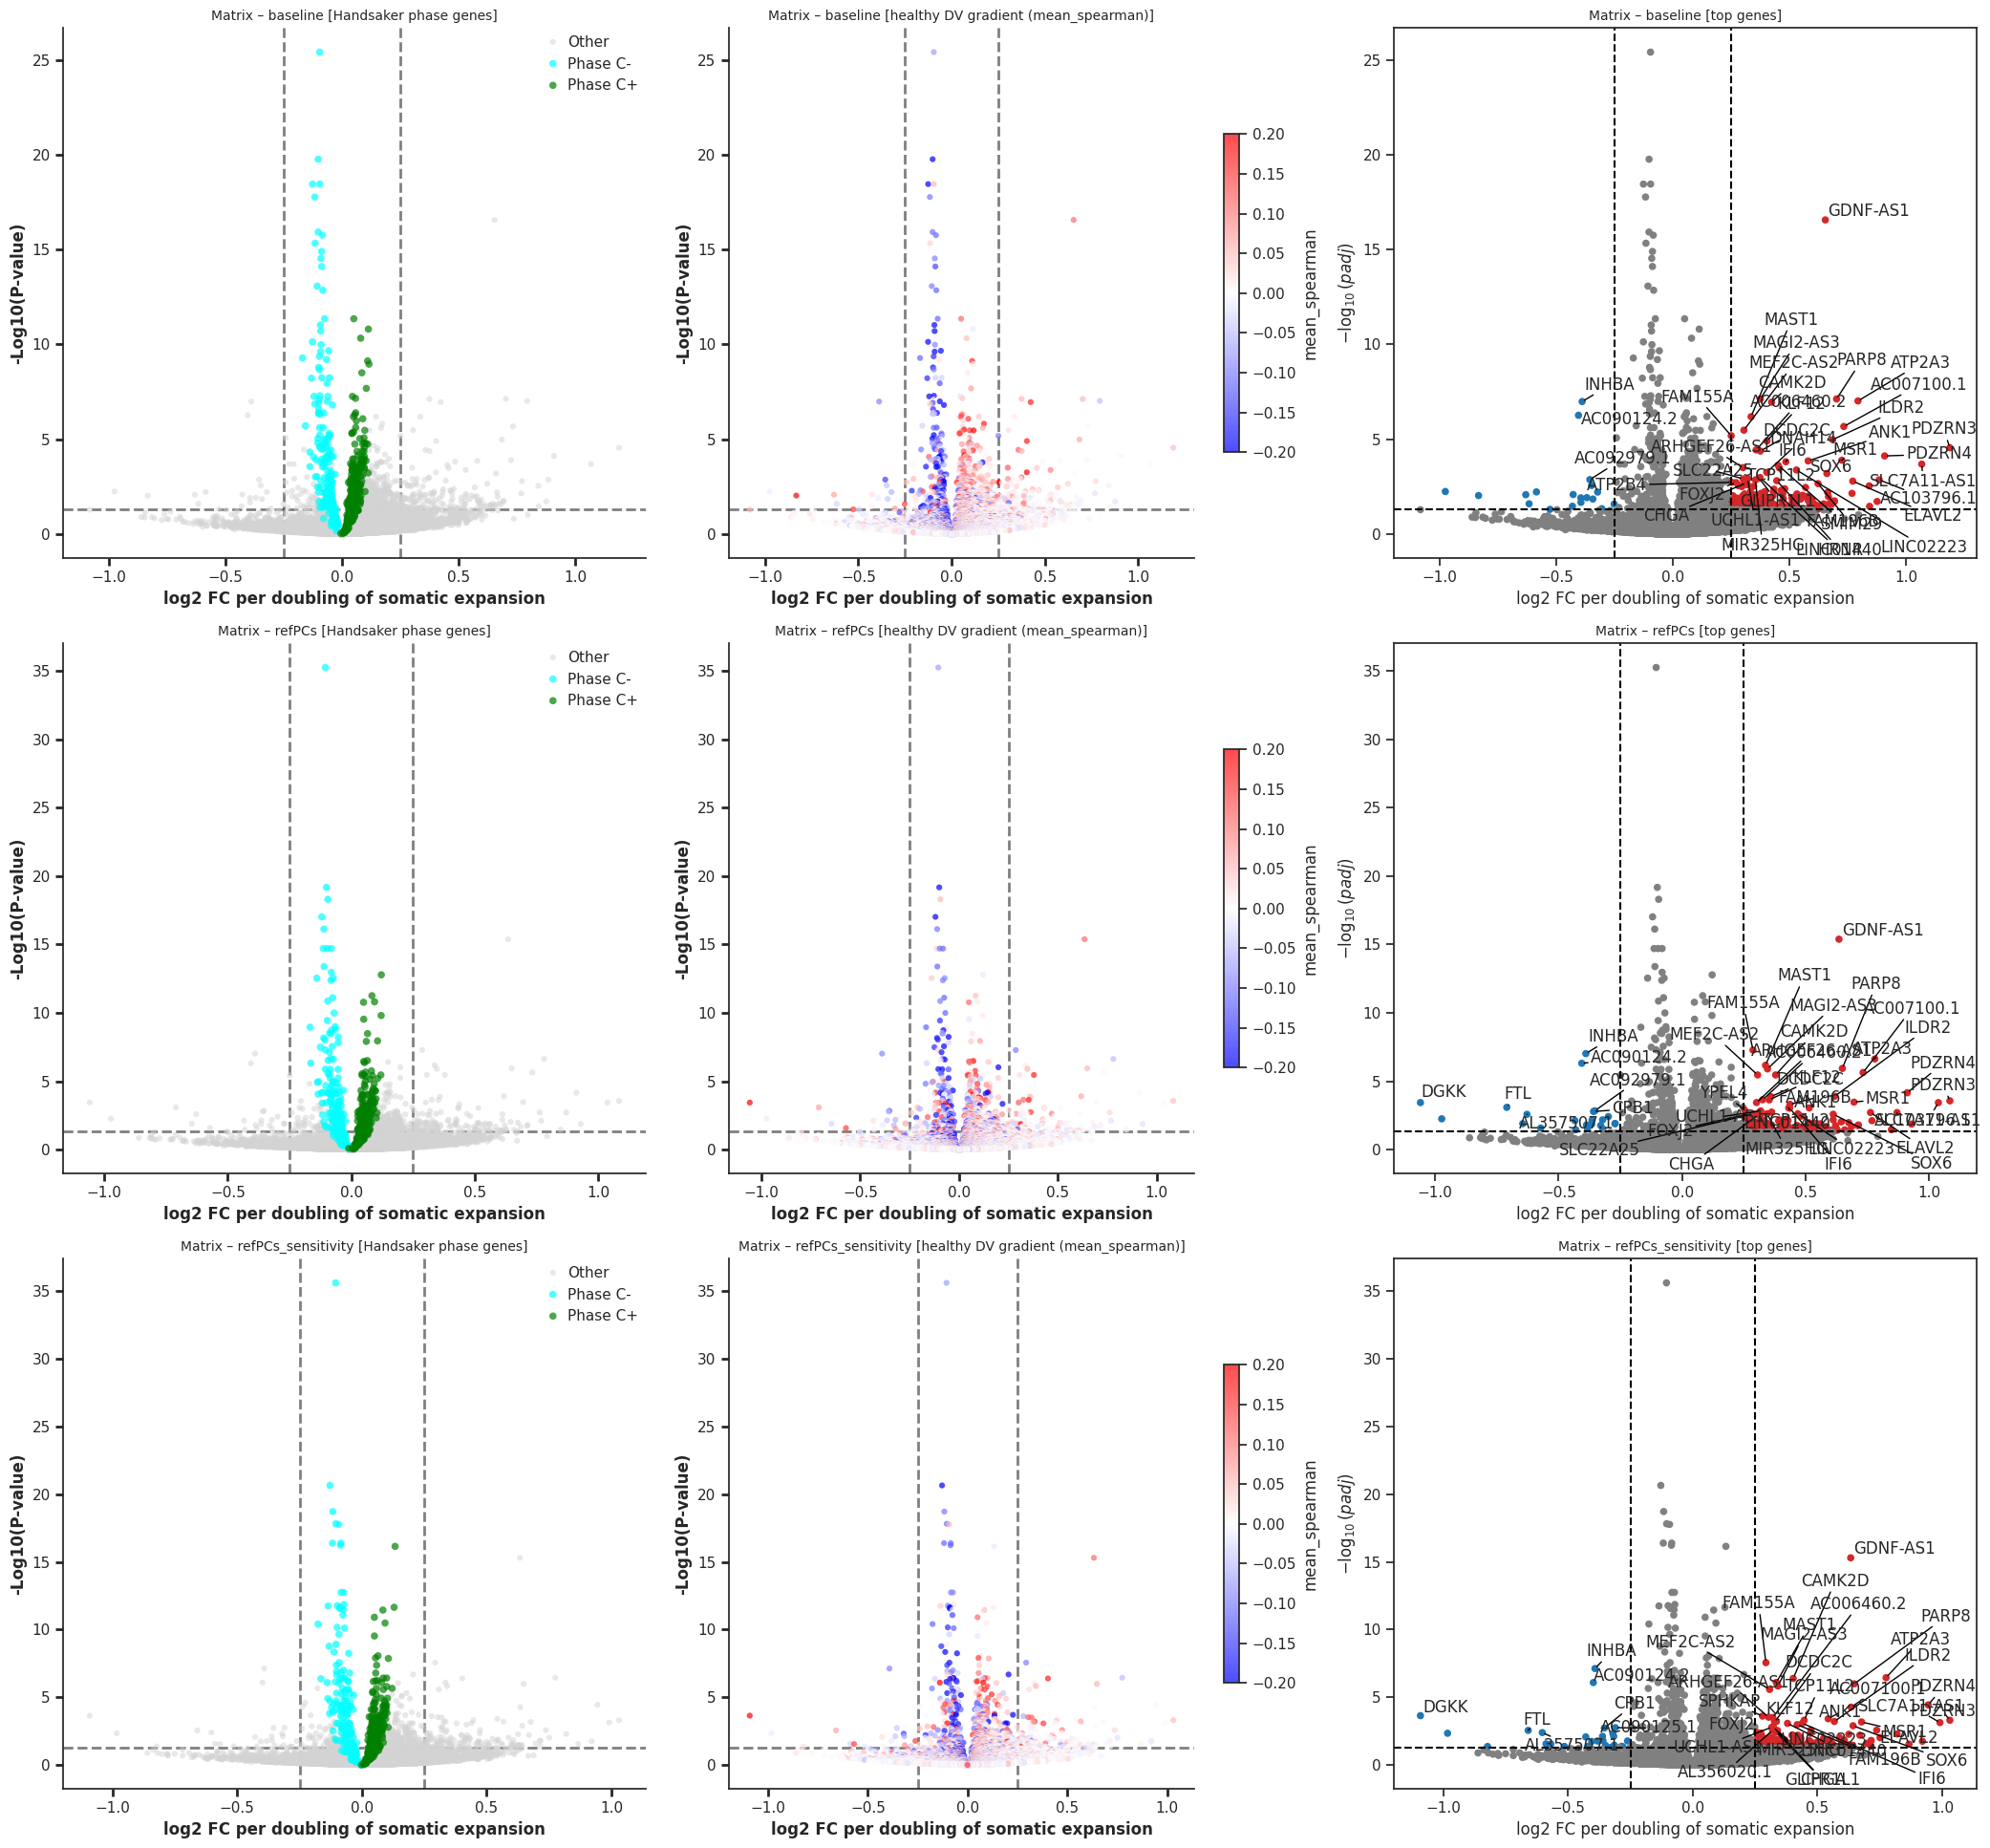

/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:944: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


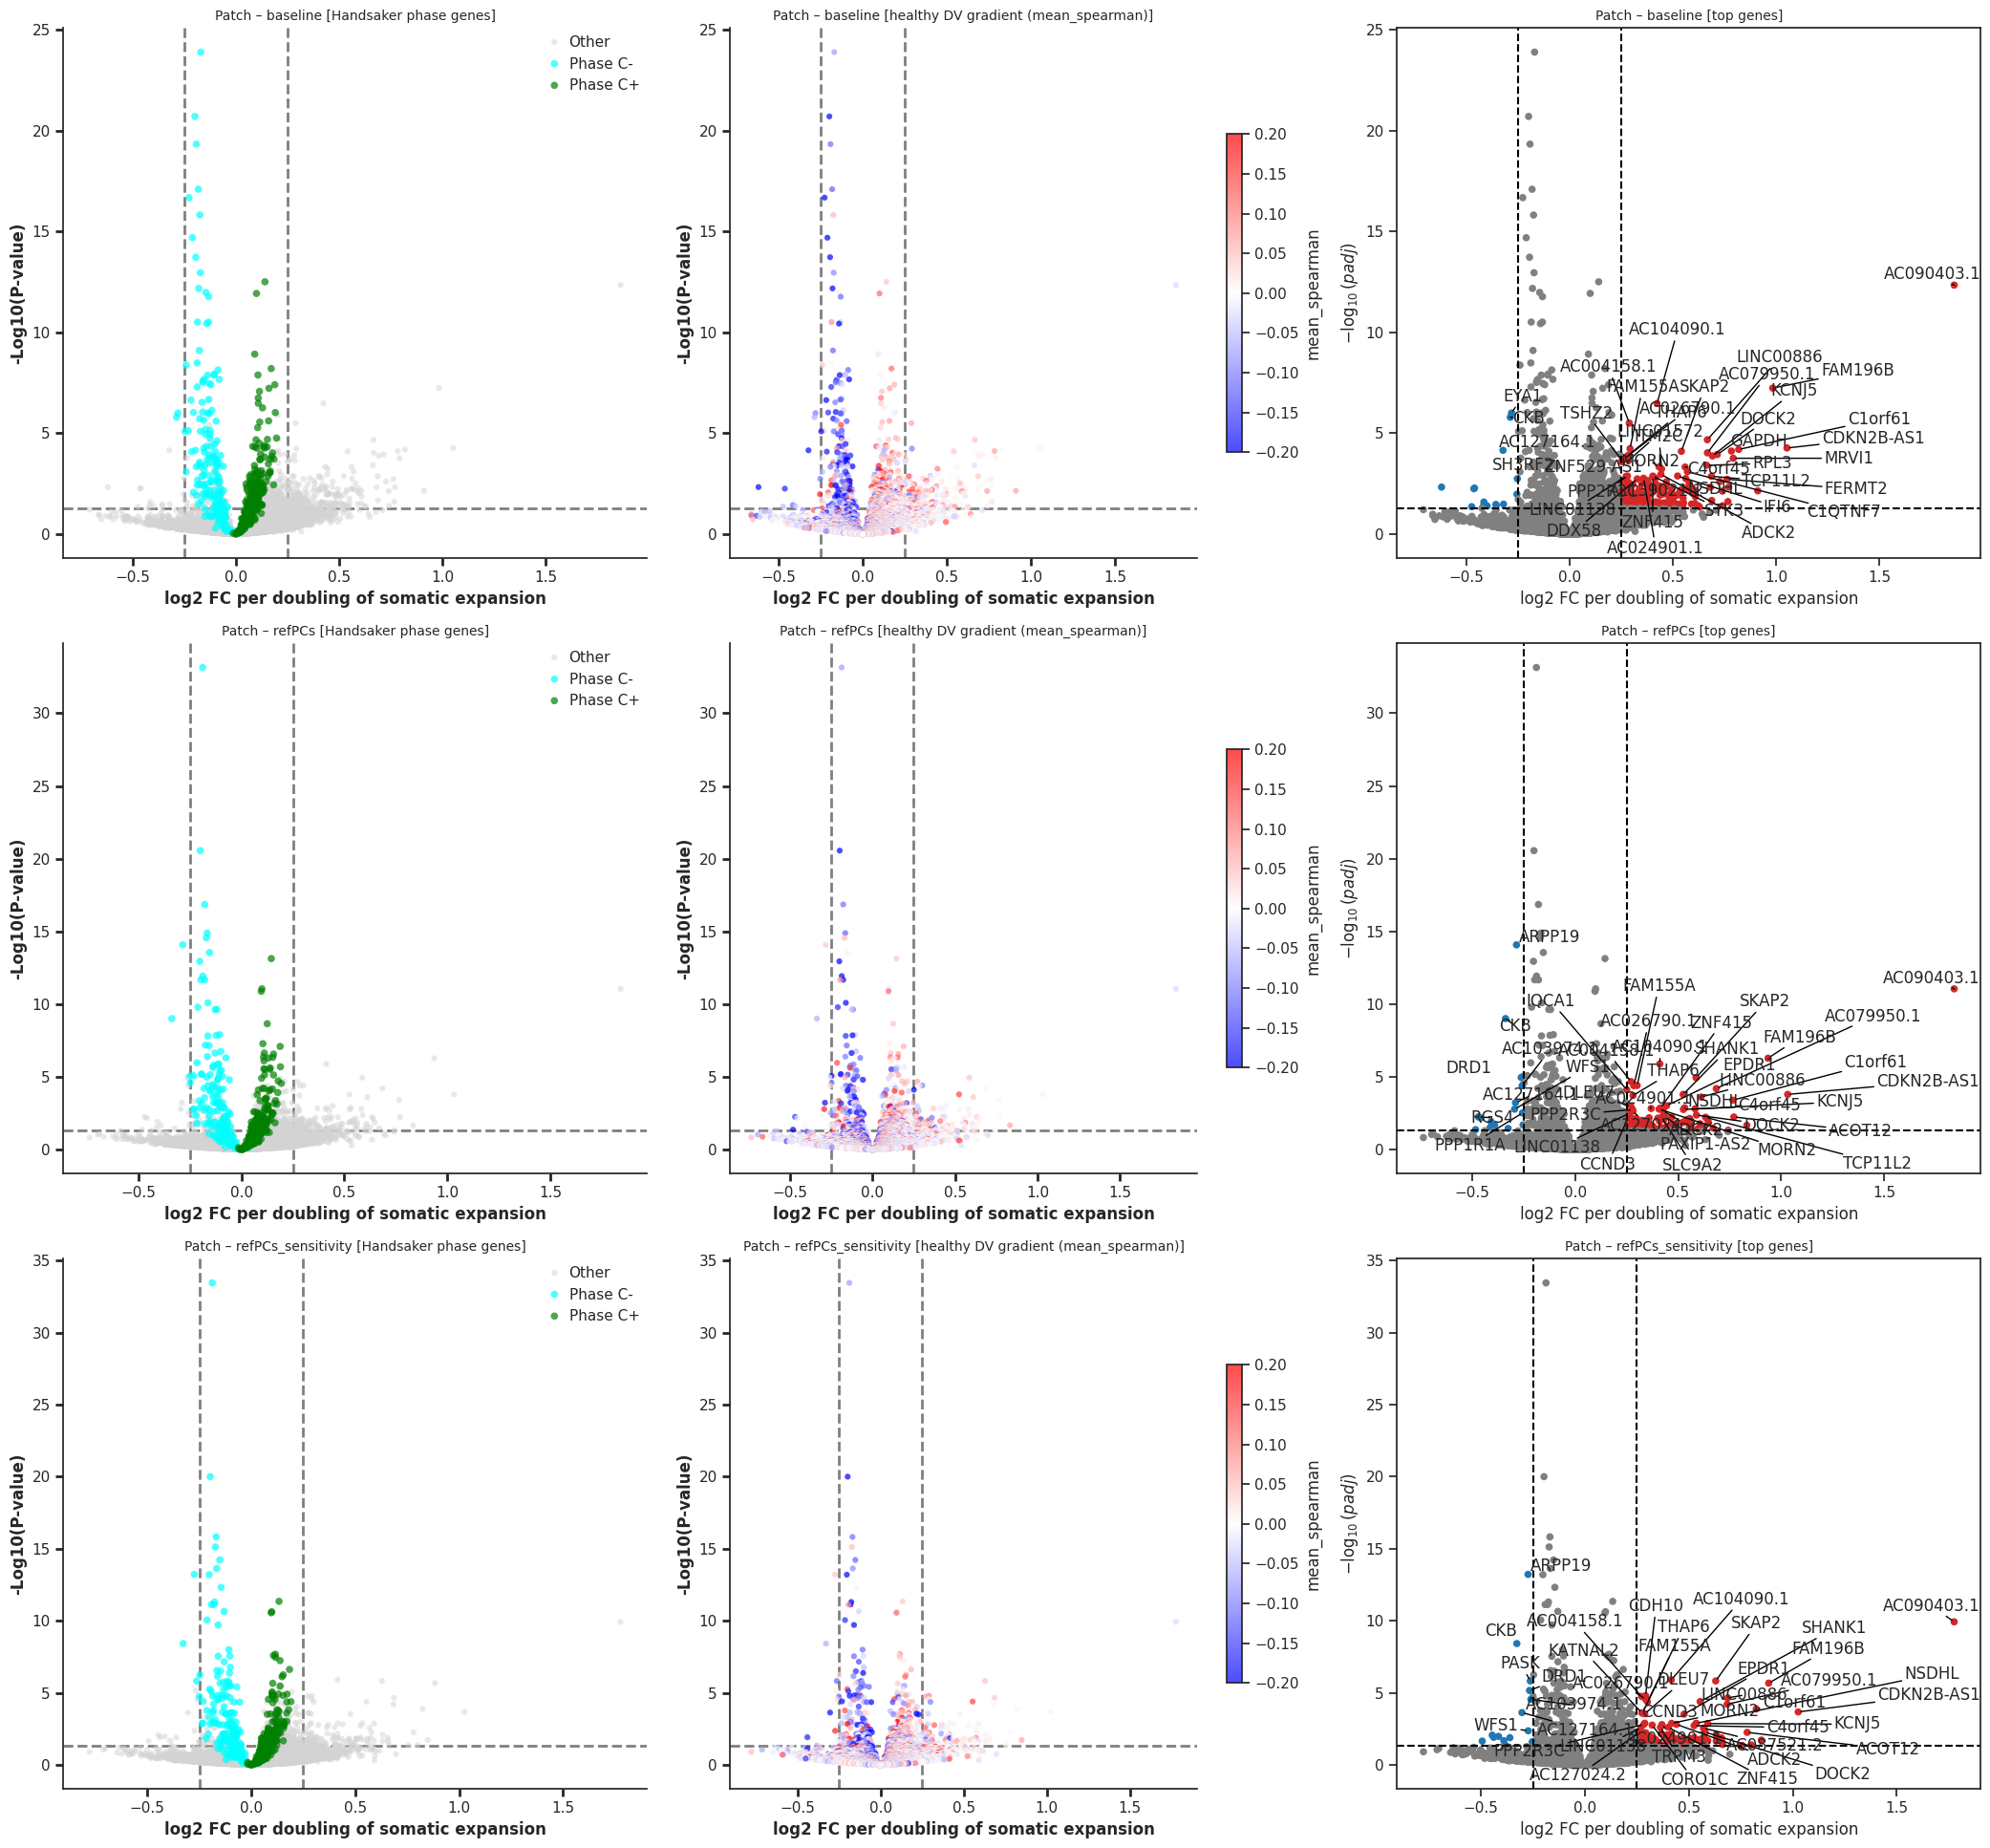

In [27]:
for ct in CELL_TYPES:
    models_ct = [m for m in MODELS if (m, ct) in res]
    fig, axes = plt.subplots(len(models_ct), 3, figsize=(21, 6.5 * len(models_ct)), squeeze=False)

    for row, model in zip(axes, models_ct):
        df = res[(model, ct)]
        ax1, ax2, ax3 = row

        # Handsaker phase genes
        DEG.plot_vulcano(df, logfc_col=LOGFC_COL, pval_col=COL_P_ADJ, gene_col=GENE_COL,
                         pval_thresh=PVAL_THR, logfc_thresh=LOGFC_THR, to_label=0,
                         categories=categories_handsaker_phases, max_y=None, ax=ax1, print_labels=False)
        # healthy dorsal-ventral gradient of each gene (red/blue = up/down along the gradient)
        DEG.plot_vulcano(df, logfc_col=LOGFC_COL, pval_col=COL_P_ADJ, gene_col=GENE_COL,
                         pval_thresh=PVAL_THR, logfc_thresh=LOGFC_THR, to_label=0,
                         color_by="mean_spearman", cmap="bwr", vmin=-0.2, vmax=0.2,
                         max_y=None, ax=ax2, print_labels=False)
        # top genes labelled
        dc.pl.volcano(df.set_index(GENE_COL).rename(columns={COL_P_ADJ: "padj", LOGFC_COL: "logFC"}),
                      x="logFC", y="padj", top=40, thr_stat=LOGFC_THR, thr_sign=PVAL_THR, max_stat=3, ax=ax3)

        for ax, lbl in zip(row, ["Handsaker phase genes", "healthy DV gradient (mean_spearman)", "top genes"]):
            ax.set_title(f"{ct} – {model} [{lbl}]", fontsize=10)
            ax.set_xlabel("log2 FC per doubling of somatic expansion")

    plt.tight_layout()
    plt.savefig(f"{RESULTS_ROOT}/figures/{ct}_volcano_all_models.png", dpi=150, bbox_inches="tight")
    plt.show()



######## Matrix: delta = 0.084 SD of PC_1 per doubling (p = 3.5e-05); corr(baseline - adjusted, positional component) = 0.84


phase,C+,C-,other,All
category,,,,
not significant,77,31,20092,20200
position-dependent (baseline only),10,18,247,275
revealed by adjustment (refPCs only),7,2,84,93
robust (both),165,120,662,947
All,259,171,21085,21515


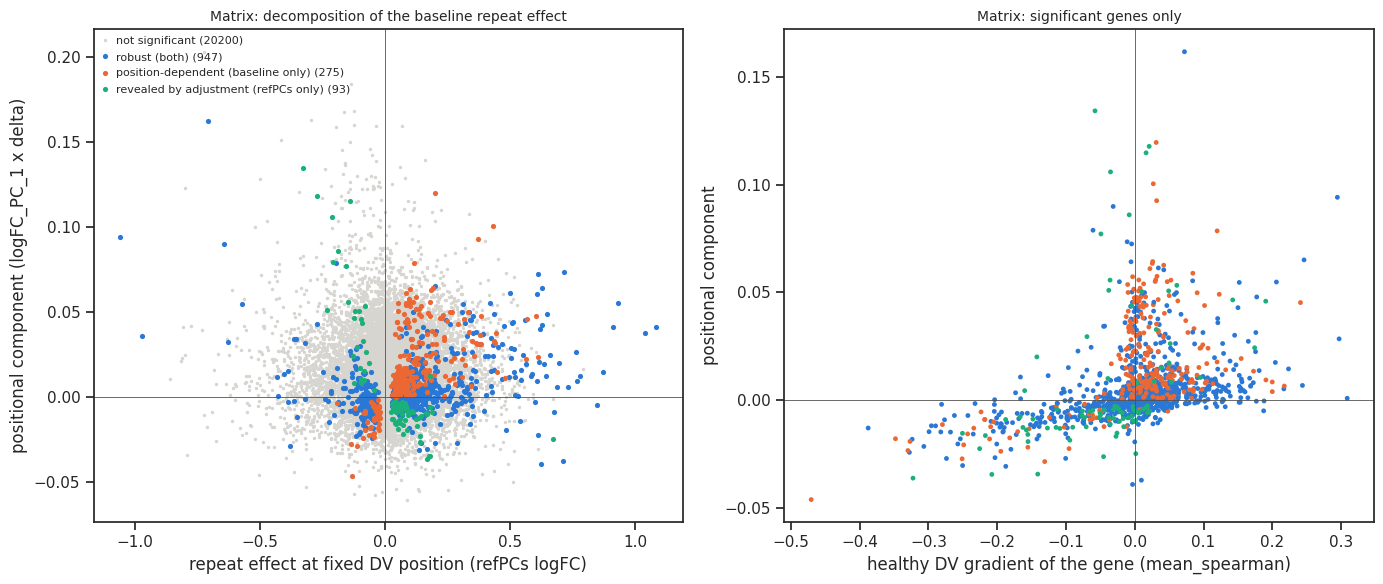


######## Patch: delta = 0.151 SD of PC_1 per doubling (p = 4.2e-05); corr(baseline - adjusted, positional component) = 0.96


phase,C+,C-,other,All
category,,,,
not significant,106,44,14352,14502
position-dependent (baseline only),26,21,252,299
revealed by adjustment (refPCs only),7,4,86,97
robust (both),120,107,421,648
All,259,176,15111,15546


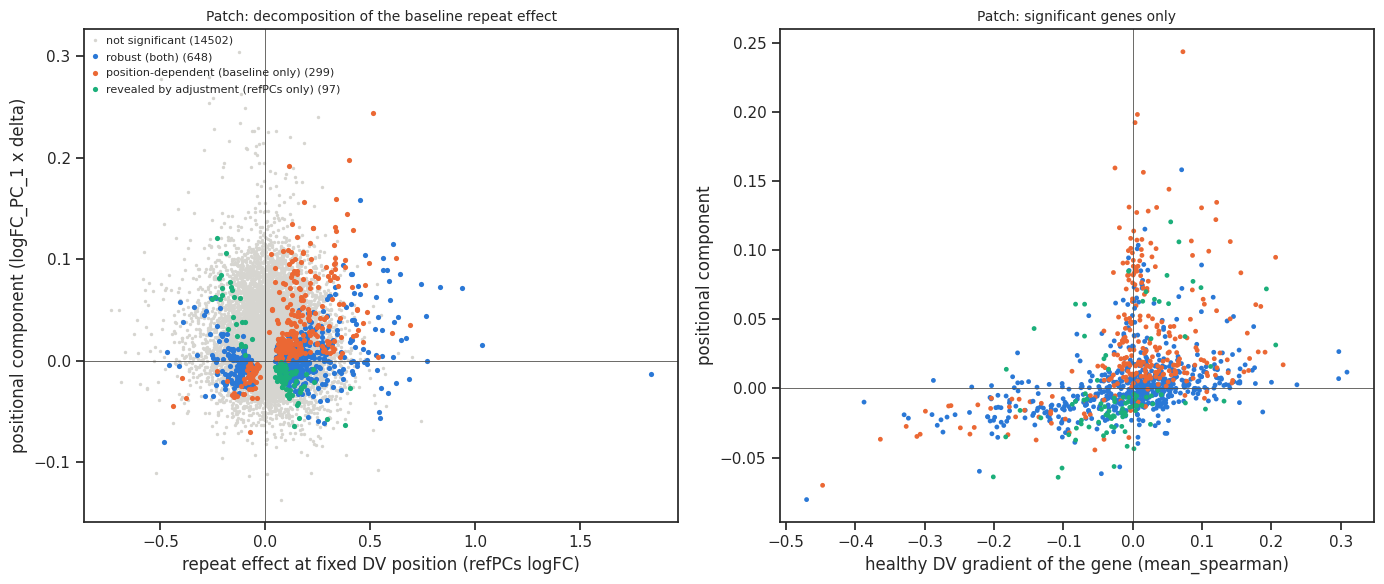

In [28]:
# Omitted-variable decomposition, gene by gene:
#     logFC_baseline  ~=  logFC_refPCs  +  logFC_PC_1(gene) * delta
# delta = how much PC_1 (z-scored, as in the NEBULA design) shifts per doubling of somatic expansion,
# from the same design table / covariates used for NEBULA.
#   logFC_refPCs             = repeat effect at fixed position on the healthy DV axis
#   logFC_PC_1(gene) * delta = "positional component": the part explained by expanded cells sitting at
#                              a different DV position - confounding OR a repeat effect that moves cells
#                              along the healthy DV axis (the data cannot separate the two)
decomp = {}
for ct in CELL_TYPES:
    if ("baseline", ct) not in res or ("refPCs", ct) not in res:
        continue
    design = pd.read_csv(f"{RESULTS_ROOT}/design_table_{ct}.csv", index_col=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = smf.mixedlm(f"PC_1 ~ {TESTED_TERM} + Age + Sex + pct_counts_mt + msn_subtype",
                          design, groups=design["DONOR"]).fit(reml=True)
    delta = fit.params[TESTED_TERM]

    b0 = res[("baseline", ct)].set_index(GENE_COL)
    b1 = res[("refPCs", ct)].set_index(GENE_COL)
    g = b0.index.intersection(b1.index)
    d = pd.DataFrame({
        "logFC_baseline": b0.loc[g, LOGFC_COL],
        "logFC_adjusted": b1.loc[g, LOGFC_COL],
        "positional_component": b1.loc[g, "logFC_PC_1"] * delta,
        "sig_baseline": b0.loc[g, COL_P_ADJ] < PVAL_THR,
        "sig_adjusted": b1.loc[g, COL_P_ADJ] < PVAL_THR,
        "mean_spearman": b1.loc[g, "mean_spearman"],
    })
    d["category"] = np.select(
        [d.sig_baseline & d.sig_adjusted & (np.sign(d.logFC_baseline) == np.sign(d.logFC_adjusted)),
         d.sig_baseline & ~d.sig_adjusted,
         ~d.sig_baseline & d.sig_adjusted],
        ["robust (both)", "position-dependent (baseline only)", "revealed by adjustment (refPCs only)"],
        "not significant")
    d["phase"] = np.select([d.index.isin(phase_c_plus.Gene), d.index.isin(phase_c_minus.Gene), d.index.isin(phase_d.Gene)],
                           ["C+", "C-", "D"], "")
    decomp[ct] = d
    d.to_csv(f"{RESULTS_ROOT}/{ct}_repeat_effect_position_decomposition.csv")

    check = np.corrcoef(d.logFC_baseline - d.logFC_adjusted, d.positional_component)[0, 1]
    print(f"\n######## {ct}: delta = {delta:.3f} SD of PC_1 per doubling (p = {fit.pvalues[TESTED_TERM]:.1e}); "
          f"corr(baseline - adjusted, positional component) = {check:.2f}")
    display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))

    palette = {"not significant": "#d6d5d0", "robust (both)": "#2a78d6",
               "position-dependent (baseline only)": "#eb6834", "revealed by adjustment (refPCs only)": "#1baf7a"}
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for cat, col in palette.items():
        m = d["category"] == cat
        axes[0].scatter(d.loc[m, "logFC_adjusted"], d.loc[m, "positional_component"], s=6 if cat == "not significant" else 14,
                        c=col, linewidths=0, label=f"{cat} ({m.sum()})", rasterized=True)
    axes[0].axhline(0, color="#52514e", lw=0.6); axes[0].axvline(0, color="#52514e", lw=0.6)
    axes[0].set_xlabel("repeat effect at fixed DV position (refPCs logFC)")
    axes[0].set_ylabel("positional component (logFC_PC_1 x delta)")
    axes[0].legend(fontsize=8, loc="upper left")
    axes[0].set_title(f"{ct}: decomposition of the baseline repeat effect", fontsize=10)

    # is the positional component simply the healthy DV gradient of each gene?
    sig = d[d.sig_baseline | d.sig_adjusted]
    axes[1].scatter(sig["mean_spearman"], sig["positional_component"], s=12,
                    c=[palette[c] for c in sig["category"]], linewidths=0)
    axes[1].axhline(0, color="#52514e", lw=0.6); axes[1].axvline(0, color="#52514e", lw=0.6)
    axes[1].set_xlabel("healthy DV gradient of the gene (mean_spearman)")
    axes[1].set_ylabel("positional component")
    axes[1].set_title(f"{ct}: significant genes only", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_ROOT}/figures/{ct}_repeat_effect_position_decomposition.png", dpi=150, bbox_inches="tight")
    plt.show()


In [31]:
for ct, d in decomp.items():
    print(f"\n######## {ct}")
    for cat in ["robust (both)", "position-dependent (baseline only)", "revealed by adjustment (refPCs only)"]:
        top = d[d["category"] == cat].reindex(d[d["category"] == cat]["logFC_baseline"].abs().sort_values(ascending=False).index)
        print(f"{cat}: {len(top)} genes")
        display(top.head(30)[["logFC_baseline", "logFC_adjusted", "positional_component", "mean_spearman", "phase"]].round(3))



######## Matrix
robust (both): 947 genes


,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase
gene,,,,,
PDZRN3,1.189,1.084,0.041,0.050,
SLC7A11-AS1,1.068,1.038,0.038,-0.005,
AL035461.2,-0.975,-0.973,0.036,-0.014,
PDZRN4,0.909,0.912,0.041,0.008,
AC103796.1,0.885,0.870,0.015,-0.001,
AC004704.1,0.876,0.929,0.055,-0.022,
AC062039.1,0.844,0.847,-0.005,0.011,
AC009478.1,0.843,0.714,0.074,-0.011,
DGKK,-0.833,-1.059,0.094,0.295,


position-dependent (baseline only): 275 genes


,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase
gene,,,,,
AL035588.1,0.659,0.610,0.024,-0.012,
AC021517.1,0.654,0.602,0.048,0.002,
GABARAP,0.640,0.432,0.100,0.027,
PLPP4,0.623,0.569,0.046,0.007,
C9orf139,0.585,0.564,0.022,-0.002,
CDKN2A,0.496,0.479,0.011,-0.006,
AC090618.1,0.484,0.442,0.038,0.001,
AC015727.1,0.475,0.440,0.032,-0.008,
FABP5,0.474,0.372,0.093,0.032,


revealed by adjustment (refPCs only): 93 genes


,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase
gene,,,,,
TTC39C-AS1,0.646,0.673,-0.025,0.002,
RPL23A,-0.208,-0.329,0.134,-0.058,
ID4,-0.190,-0.234,0.051,-0.038,
RPL21,-0.183,-0.271,0.118,0.021,
PEBP4,0.179,0.186,-0.009,-0.017,
TRPC4,0.174,0.179,-0.006,0.018,
AC098484.3,0.171,0.179,0.012,NaN,
AC009435.1,0.159,0.166,-0.010,0.001,
AC004834.1,0.154,0.162,-0.010,-0.003,


... (2 outputs left out)

position-dependent (baseline only): 299 genes


,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase
gene,,,,,
TRHDE,0.766,0.692,0.035,0.025,
FTL,0.740,0.513,0.244,0.072,
RPL3,0.663,0.339,0.160,-0.026,
DAPL1,0.629,0.622,0.101,0.034,
NCALD,0.624,0.605,0.027,0.019,
TUBB4B,0.608,0.417,0.128,0.022,
STMN1,0.579,0.388,0.144,0.052,
RPS15A,0.572,0.401,0.198,0.007,
IFI6,0.562,0.379,0.092,0.010,


revealed by adjustment (refPCs only): 97 genes


,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase
gene,,,,,
IL20RB,0.382,0.404,-0.027,-0.016,
NCKAP5,0.321,0.380,-0.064,-0.201,
ASB18,0.222,0.292,-0.058,-0.102,
STARD4-AS1,0.217,0.226,-0.008,-0.071,
CTNNBIP1,0.213,0.231,-0.021,-0.030,
PPP1R1A,-0.195,-0.255,0.061,-0.069,
SAE1,0.180,0.192,-0.013,-0.041,
AP1S1,-0.169,-0.241,0.063,0.014,
AC098850.4,0.155,0.183,-0.025,NaN,


# Assumptions and limitations

* **Different technologies.** BICAN is Slide-tags snRNA-seq; HD DeepDive is 10x snRNA-seq. Depth, capture and gene annotation differ. Genes are matched on symbol (~21k shared; BICAN has no Ensembl IDs). The scaler uses BICAN mean and variance, so HD scores carry a dataset offset (`shift_sd`), which the model intercept absorbs. `var_ratio` shows whether the *spread* along each axis transfers. A PC with good BICAN spatial metrics but a poor `var_ratio` should not be trusted as a spatial covariate in HD.
* **Spatial meaning is only verified in BICAN.** HD has no coordinates, and its `zone` labels were predicted by expression mapping to BICAN, so HD zone η² is a consistency check, not truth.
* **Not purely spatial.** PCs also pick up donor, D1/D2, quality and any healthy biology. Reading PCs as "spatial" requires a high `|rho_r|` or zone η² in BICAN.
* **Repeat-associated PCs.** If a selected PC is associated with `somatic_expansion`, the PC model removes that shared component. The baseline-vs-PC comparison and the phase C control show how much this matters, but cannot decide between confounding by position and repeat-driven expression change.
* **Repeat measurement.** One HTT molecule per cell. Cells with a WT-allele read, or no read, are excluded. Cells that have a read are enriched for higher depth and HTT expression. Very long reads may include artefacts (`MAX_CAGLENGTH` lets you test this).
* **Phase D excluded.** `-phase_D` cells (identity loss at > ~150 CAG) are not Matrix/Patch-labelled, so results describe repeat effects *before* phase D. CAG ranges therefore differ between donors.
* **Few donors, unbalanced.** 8 HD donors, one of which supplies about a third of the Matrix cells, and Patch is small. Between-donor differences in somatic expansion are partly confounded with age and disease stage; Age and Sex are nuisance terms with very few degrees of freedom and should not be interpreted.

**Alternatives, if the projected PCs transfer poorly.** These are not implemented; they are options.
1. Fit the reference PCA on BICAN *stable spatial-gradient genes* only (`genes_correlation/df_corr.csv`) rather than HVGs. This gives cleaner spatial axes but less coverage of other structure.
2. Use a single transcriptomic dorsal–ventral covariate (`gradient_score`, as in `Handsaker_DEG_factors.ipynb`).
3. Use a joint embedding of BICAN and HD (Harmony / scVI) and transfer coordinates. This is **not recommended**, because disease-associated variation would help define the axes, which defeats the purpose of a healthy reference.